In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import seaborn as sns
sns.set_palette('colorblind')
from matplotlib.pyplot import tight_layout
# ##SETTING PARAMS FOR MATPLOTLIB FIGURES
plt.rcParams.update({"figure.figsize": (6, 6),
                 "axes.facecolor": "white",
                 "axes.edgecolor": "black"})
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
##set font size
font = {'family': 'sans-serif',
       'weight': 'normal',
       'size': 14}
plt.rc('font', **font)
# ##PANDAS PLOTTING
pd.plotting.register_matplotlib_converters()

In [2]:
# Imports
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from matplotlib.patches import Patch
import glob
import os
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from tqdm import tqdm
import codecs
import csv
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# For inline plots in Jupyter
%matplotlib inline    

In [3]:
!pip install -U kaleido

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


## Step 2 : Import files

In [4]:
data_directory_merged = "/home/paulharford/college/project/project_data/processed/WEATHERED_merged_v2.csv"
full_path_merged = os.path.abspath(data_directory_merged)

In [5]:
df_final_expanded = pd.read_csv(full_path_merged)


In [6]:
df_final_expanded.isnull().sum()

region                      0
date                        0
age_group                   0
gender                      0
hip_fracture_count          0
weather_event               0
warning_phenomenon          0
warning_severity            0
warning_severity_numeric    0
counties_in_region          0
county_weight               0
female                      0
male                        0
total                       0
population                  0
log_population              0
month                       0
season                      0
is_winter                   0
is_spring                   0
is_summer                   0
is_autumn                   0
orange_warning              0
red_warning                 0
yellow_warning              0
orange_warning_lag          0
red_warning_lag             0
cold_weather                0
wind_weather                0
precipitation               0
heat_weather                0
no_adverse_weather          0
cold_lag                    0
wind_lag  

In [7]:
## final model formula - test showed standard poisson was good same /model/formula as tests 
formula = """
hip_fracture_count ~ 
C(weather_event, Treatment(reference=0)) +
C(warning_severity_numeric, Treatment(reference=0)) +
C(gender, Treatment(reference='Female')) +
county_weight + 
C(region, Treatment(reference='HSE South West')):C(weather_event, Treatment(reference=0)) +
C(gender, Treatment(reference='Female')):C(weather_event, Treatment(reference=0))
"""
offset = df_final_expanded["log_population"]
poisson_model = smf.glm(
    formula=formula, 
    data=df_final_expanded, 
    family=sm.families.Poisson(),offset=offset, 
    )

# fit the Poisson model
poisson_results_2 = poisson_model.fit()

# Calculate the dispersion parameter
dispersion = poisson_results_2.deviance / poisson_results_2.df_resid
print(f"Dispersion parameter: {dispersion:.4f}")

#print("Residual Deviance:", quasi_poisson_results.deviance)
#print("Degrees of Freedom:", quasi_poisson_results.df_resid)

Dispersion parameter: 0.9118


In [8]:
# Extract all unique regions from your dataset
all_regions = df_final_expanded['region'].unique().tolist()

# Print the regions to verify
print("HSE Regions included in analysis:")
for region in all_regions:
    print(f"- {region}")

HSE Regions included in analysis:
- HSE Dublin and Midlands
- HSE Dublin and North East
- HSE Dublin and South East
- HSE Mid West
- HSE South West
- HSE West and North West


In [9]:
def calculate_hip_fracture_rates(model, df, optional_vars=None, reference_population=50000):
    """
    Calculate hip fracture rates using the Poisson model, focusing only on regions and gender.
    
    Parameters:
    -----------
    model : GLM results
    df : pandas DataFrame
        Dataset used for modeling
    optional_vars : dict or None, optional 
        Dictionary of optional variables to include (e.g., {'is_winter': 1})
    reference_population : int, optional (default=100000)
        Population size to standardize rates for
    
    Returns:
    --------
    pandas DataFrame
        Table of rates by region, gender, and warning severity
    """
    # Initialize empty list for results
    results = []
    
    # Get unique values
    regions = sorted(df['region'].unique().tolist())
    genders = sorted(df['gender'].unique().tolist())
    
    # Set up the optional variables
    if optional_vars is None:
        optional_vars = {}  
    
    # Define scenarios based on the model
    scenarios = [
        {"name": "Baseline", "warning_color": "None", "weather_event": 0, "warning_severity_numeric": 0},
        {"name": "Yellow Warning", "warning_color": "Yellow", "weather_event": 1, "warning_severity_numeric": 1},
        {"name": "Orange Warning", "warning_color": "Orange", "weather_event": 1, "warning_severity_numeric": 2},
        {"name": "Red Warning", "warning_color": "Red", "weather_event": 1, "warning_severity_numeric": 3}
    ]
    
    for region in regions:
        for gender in genders:
            # Get data for this demographic group
            demo_data = df[(df['region'] == region) & (df['gender'] == gender)]
            
            if len(demo_data) == 0:
                continue
            
            # Get the population for this demographic
            if 'population' in demo_data.columns:
                demo_population = demo_data['population'].mean()
            elif 'total' in demo_data.columns:
                demo_population = demo_data['total'].mean()
            else:
                # Try to determine population from gender-specific columns
                gender_col = gender.lower()
                if gender_col in demo_data.columns:
                    demo_population = demo_data[gender_col].mean()
                else:
                    continue 
            
            if pd.isna(demo_population) or demo_population <= 0:
                continue
            
            for scenario in scenarios:
                # Create a new DF with exactly one row
                pred_row = pd.DataFrame({col: [0] for col in df.columns})
                
                # Set key values
                pred_row['region'] = region
                pred_row['gender'] = gender
                if 'age_group' in pred_row.columns:
                    # If age_group still exists in the model, use the most common value
                    most_common_age = df['age_group'].mode()[0]
                    pred_row['age_group'] = most_common_age
                
                pred_row['weather_event'] = scenario["weather_event"]
                pred_row['warning_severity_numeric'] = scenario["warning_severity_numeric"]
                
                # Add any optional variables
                for var_name, var_value in optional_vars.items():
                    if var_name in pred_row.columns:
                        pred_row[var_name] = var_value
                
                # Set the population and log_population variables
                pred_row['population'] = demo_population
                pred_row['log_population'] = np.log(demo_population)
                
                try:
                    # Get predicted value 
                    predicted_rate = model.predict(pred_row).iloc[0]
                    
                    # Scale to reference population (e.g., per 50,000)
                    standardized_rate = predicted_rate * reference_population
                    
                    # Store result 
                    results.append({
                        'Region': region,
                        'Gender': gender,
                        'Warning Color': scenario["warning_color"],
                        'Scenario': scenario["name"],
                        f'Rate per {reference_population:,}': standardized_rate
                    })
                except Exception as e:
                    print(f"Error predicting for {region}, {gender}, scenario={scenario['name']}: {str(e)}")
                    # Additional diagnostic output
                    if hasattr(model, 'model') and hasattr(model.model, 'exog_names'):
                        print(f"Model formula terms: {model.model.exog_names}")
                    print(f"Prediction data columns: {pred_row.columns.tolist()}")
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Sort by key dimensions
    if not results_df.empty:
        results_df = results_df.sort_values(['Region', 'Gender', 'Warning Color'])
    
    return results_df

def plot_rates_by_region(rates_df, reference_population=50000, save_path=None):
    """
    Create bar plots showing hip fracture rates by gender and warning severity for each region,
    including percentage changes from baseline.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        Output from calculate_hip_fracture_rates function
    reference_population : int, optional (default=100000)
        Population size used for standardization
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    None (displays plots)
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import seaborn as sns
    
    # Check if we have any data to plot
    if rates_df.empty:
        print("No data available to plot.")
        return
    
    # Define colors for warning levels
    warning_colors = {
        'None': 'gray',
        'Yellow': 'gold',
        'Orange': 'darkorange',
        'Red': 'darkred'
    }
    
    # Get unique regions
    regions = rates_df['Region'].unique()
    
    # For each region, create a separate figure
    for region in regions:
        region_data = rates_df[rates_df['Region'] == region]
        
        # Get genders for this region
        genders = sorted(region_data['Gender'].unique())
        
        # Check if we have any genders
        if len(genders) == 0:
            print(f"No data available for region {region}")
            continue
        
        # Set up the plot 
        fig = plt.figure(figsize=(12, 8))
        plt.title(f'Hip Fracture Rates in {region} per {reference_population:,} Population', 
                  fontsize=16, fontweight='bold')
        
        # Set up positions for grouped bars
        gender_positions = {gender: i for i, gender in enumerate(genders)}
        bar_width = 0.2
        
        # Track legend handles and labels
        handles = []
        labels = []
        
        # Initialize table data
        table_data = []
        
        # Plot bars for each warning color
        for warning_color, color in warning_colors.items():
            warning_data = region_data[region_data['Warning Color'] == warning_color]
            
            for gender, pos in gender_positions.items():
                gender_warning_data = warning_data[warning_data['Gender'] == gender]
                if not gender_warning_data.empty:
                    rate_col = f'Rate per {reference_population:,}'
                    rate = gender_warning_data[rate_col].values[0]
                    
                    # Calculate position for this bar
                    x_pos = pos + (list(warning_colors.keys()).index(warning_color) * bar_width)
                    
                    # Create bar
                    bar = plt.bar(x_pos, rate, width=bar_width, color=color, 
                              label=f'{warning_color} Warning')
                    
                    # Add to legend handles only once per warning color
                    if gender == genders[0]:
                        handles.append(bar[0])
                        labels.append(f'{warning_color} Warning')
                    
                    # Add text with rate value
                    plt.text(x_pos, rate, f'{rate:.1f}', 
                             ha='center', va='bottom', fontsize=9)
                    
                    # Add percentage change for non-baseline scenarios
                    if warning_color != 'None':
                        # Find the baseline rate for this gender
                        baseline_data = region_data[(region_data['Gender'] == gender) & 
                                                  (region_data['Warning Color'] == 'None')]
                        
                        if not baseline_data.empty:
                            baseline_rate = baseline_data[rate_col].values[0]
                            
                            if baseline_rate > 0:
                                # Calculate percentage change from baseline for this specific gender
                                pct_change = ((rate - baseline_rate) / baseline_rate) * 100
                                
                                # Position the percentage change text below the rate value
                                plt.text(x_pos, rate * 0.5, f'({pct_change:+.1f}%)', 
                                         ha='center', va='center', fontsize=15, 
                                         color='white' if pct_change < 0 else 'black',
                                         fontweight='bold')
        
        # Build table data for gender differences (without difference column)
        for warning_color in ['Yellow', 'Orange', 'Red']:  # Exclude 'None'
            if len(genders) > 1:
                male_data = region_data[(region_data['Gender'] == 'Male') & 
                                      (region_data['Warning Color'] == warning_color)]
                female_data = region_data[(region_data['Gender'] == 'Female') & 
                                        (region_data['Warning Color'] == warning_color)]
                
                male_baseline = region_data[(region_data['Gender'] == 'Male') & 
                                          (region_data['Warning Color'] == 'None')]
                female_baseline = region_data[(region_data['Gender'] == 'Female') & 
                                            (region_data['Warning Color'] == 'None')]
                
                if (not male_data.empty and not female_data.empty and 
                    not male_baseline.empty and not female_baseline.empty):
                    
                    rate_col = f'Rate per {reference_population:,}'
                    male_rate = male_data[rate_col].values[0]
                    female_rate = female_data[rate_col].values[0]
                    male_baseline_rate = male_baseline[rate_col].values[0]
                    female_baseline_rate = female_baseline[rate_col].values[0]
                    
                    if male_baseline_rate > 0 and female_baseline_rate > 0:
                        male_pct = ((male_rate - male_baseline_rate) / male_baseline_rate) * 100
                        female_pct = ((female_rate - female_baseline_rate) / female_baseline_rate) * 100
                        
                        table_data.append([f"{warning_color} Warning", f"{male_pct:+.1f}%", 
                                         f"{female_pct:+.1f}%"])
        
        # Set plot details
        plt.xticks([p + (len(warning_colors) * bar_width) / 2 - bar_width/2 for p in range(len(gender_positions))], 
                   gender_positions.keys())
        plt.xlabel('Gender', fontsize=12)
        plt.ylabel(f'Rate per {reference_population:,}', fontsize=12)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        
        # Add legend
        plt.legend(handles, labels, loc='upper right')
        
        # Add table if we have data
        if table_data and len(genders) > 1:
            # Add table at the bottom (without difference column)
            columns = ['Warning Level', 'Male', 'Female']
            table = plt.table(cellText=table_data,
                            colLabels=columns,
                            cellLoc='center',
                            loc='bottom',
                            bbox=[0.2, -0.35, 0.6, 0.25])
            table.auto_set_font_size(False)
            table.set_fontsize(12)
            table.scale(1, 1.5)
        
        plt.tight_layout(rect=[0, 0.15, 1, 1.5] if table_data and len(genders) > 1 else None)
        
        # Save the plot if a path is provided
        if save_path:
            # Create a region-specific filename if a directory is provided
            if save_path.endswith('/') or save_path.endswith('\\'):
                file_path = f"{save_path}hip_fracture_rates_{region.replace(' ', '_')}.png"
            else:
                file_path = save_path
            plt.savefig(file_path, dpi=300, bbox_inches='tight')
            print(f"Plot saved to: {file_path}")
        
        plt.show()
        
def plot_comparative_rates(rates_df, reference_population=50000):
    """
    Create a single plot comparing hip fracture rates across all regions by gender.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        Output from calculate_hip_fracture_rates function
    reference_population : int, optional (default=100000)
        Population size used for standardization
    
    Returns:
    --------
    None (displays plot)
    """    
    # Check if we have any data to plot
    if rates_df.empty:
        print("No data available to plot.")
        return
    
    # Define warning colors
    warning_colors = {
        'None': 'gray',
        'Yellow': 'gold',
        'Orange': 'darkorange',
        'Red': 'darkred'
    }
    
    
    plt.figure(figsize=(15, 10))
    warning_levels = sorted(rates_df['Warning Color'].unique().tolist())
    
    for i, warning in enumerate(warning_levels):
        plt.subplot(2, 2, i+1)  # Assumes 4 warning levels
        
        warning_data = rates_df[rates_df['Warning Color'] == warning]
        
        # Pivot the data to get regions as columns and genders as rows
        pivot_data = warning_data.pivot_table(
            index='Gender', 
            columns='Region',
            values=f'Rate per {reference_population:,}'
        )
        
        # Plot as bar chart
        ax = pivot_data.plot(kind='bar', ax=plt.gca(), color=sns.color_palette("husl", len(pivot_data.columns)))
        
        plt.title(f'{warning} Warning Hip Fracture Rate', fontsize=14)
        plt.ylabel(f'Rate per {reference_population:,}', fontsize=12)
        plt.xlabel('Gender', fontsize=12)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend(title='Region')
    
    plt.suptitle(f'Comparison of Hip Fracture Rates by Region and Gender per {reference_population:,} Population', 
                fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    plt.show()



Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_Dublin_and_Midlands.png


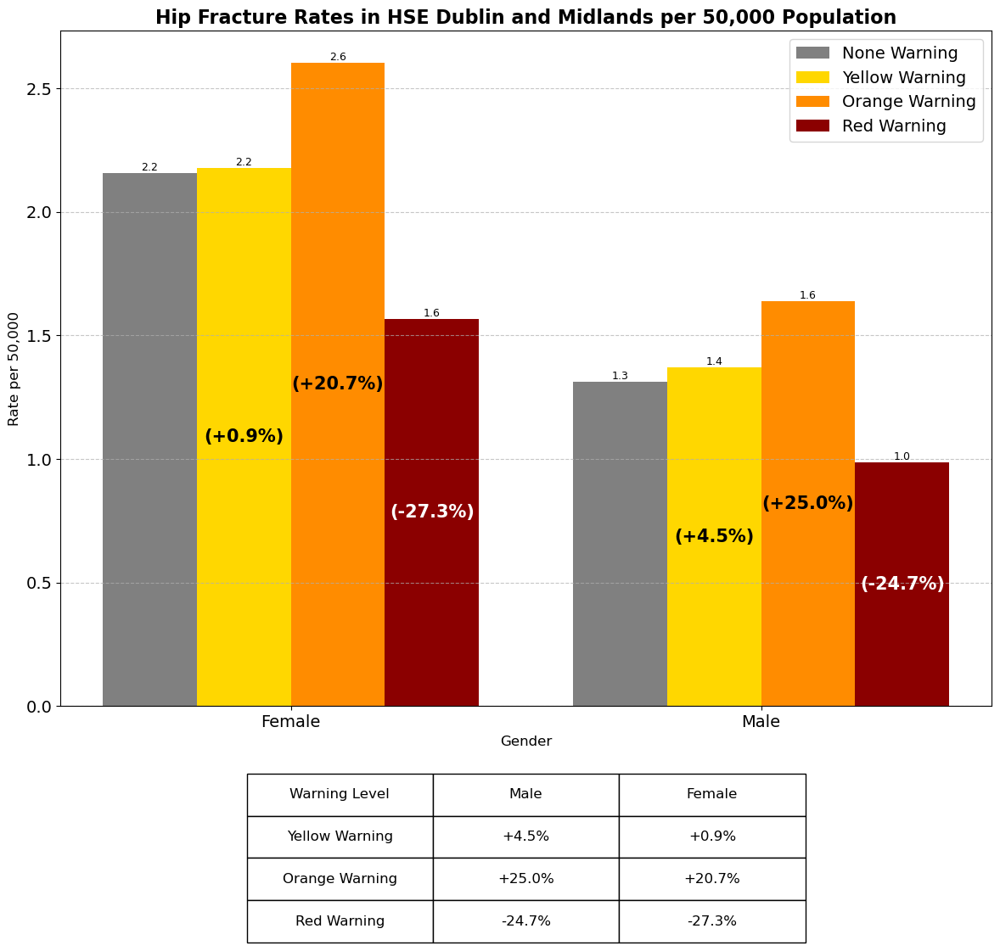

Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_Dublin_and_North_East.png


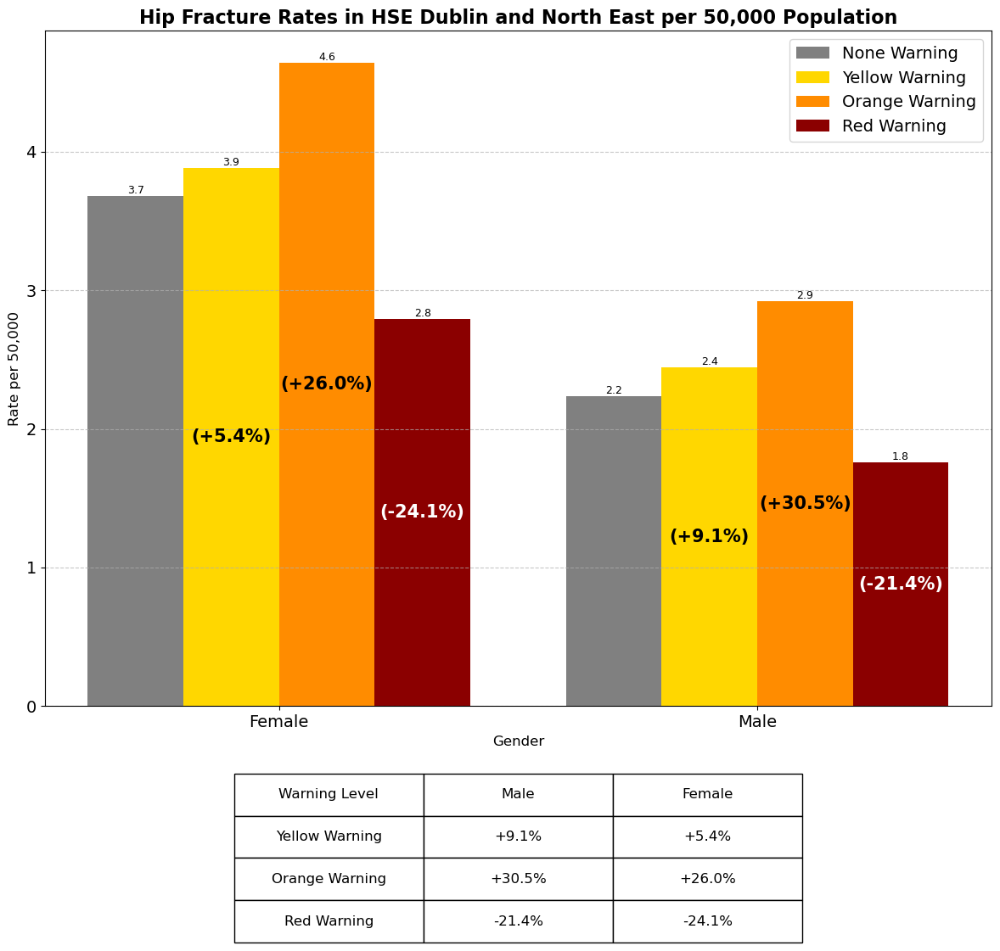

Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_Dublin_and_South_East.png


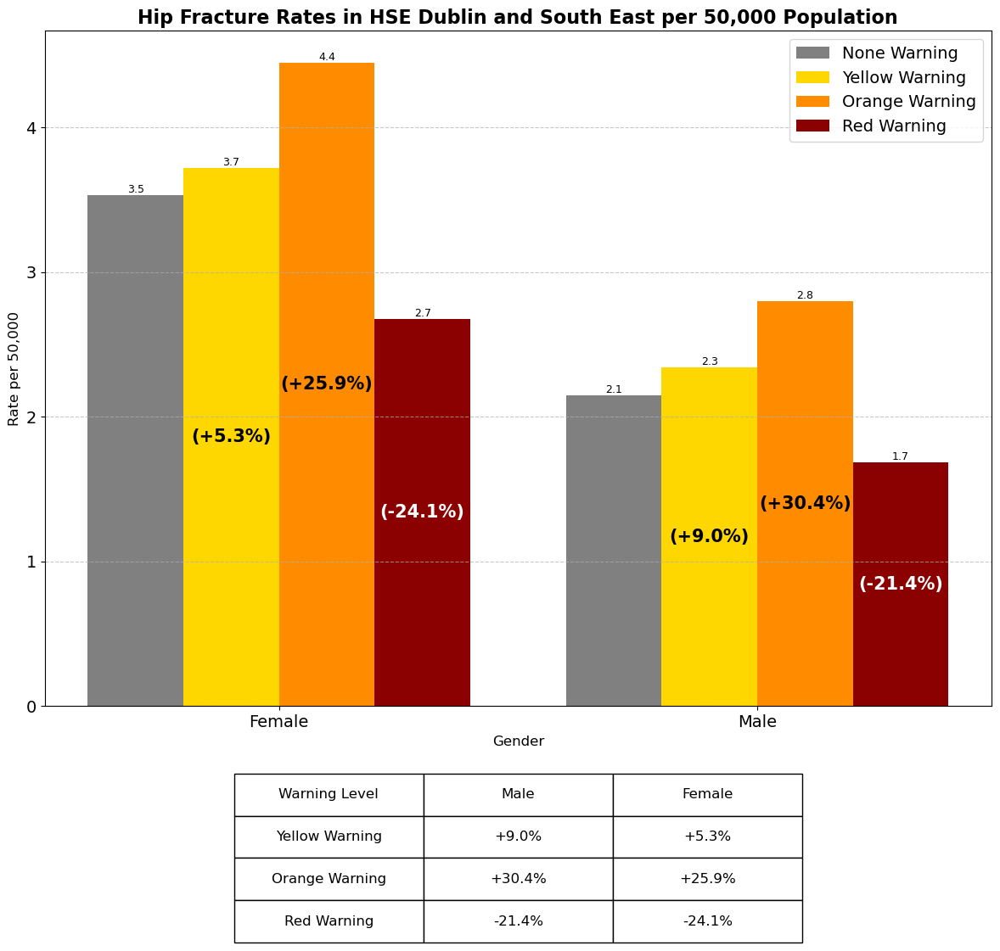

Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_Mid_West.png


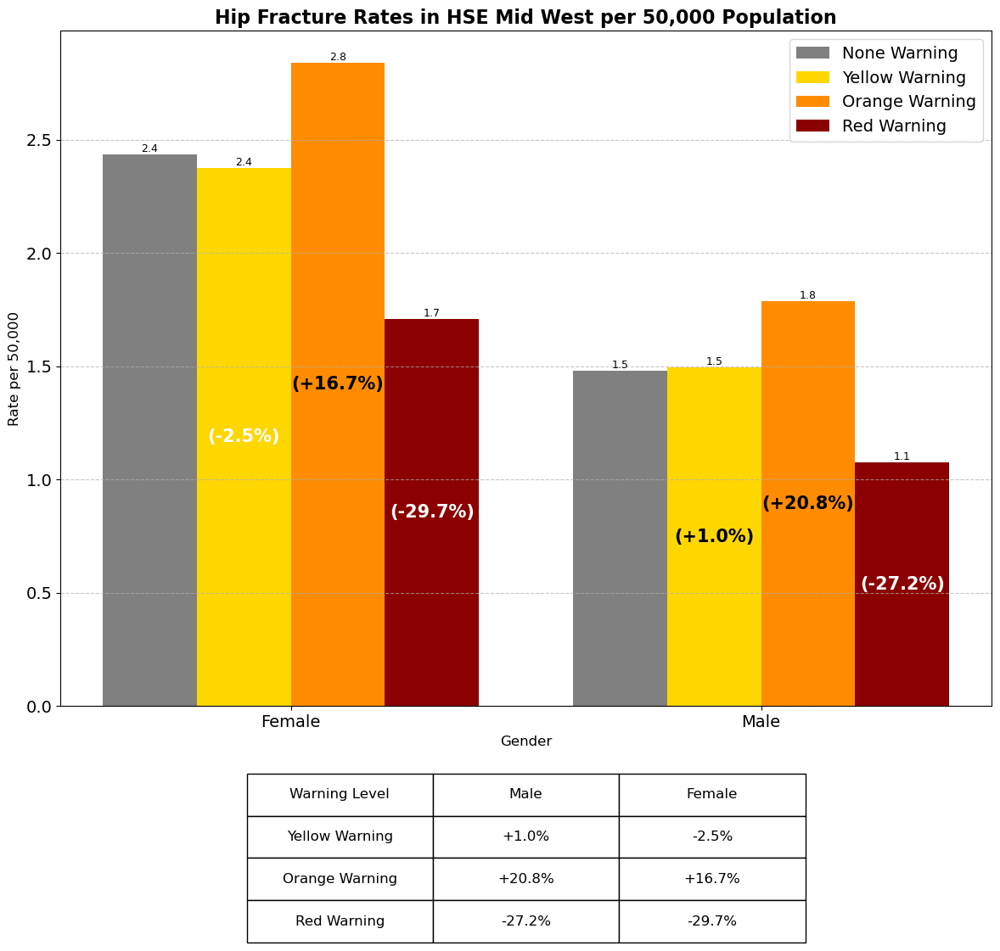

Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_South_West.png


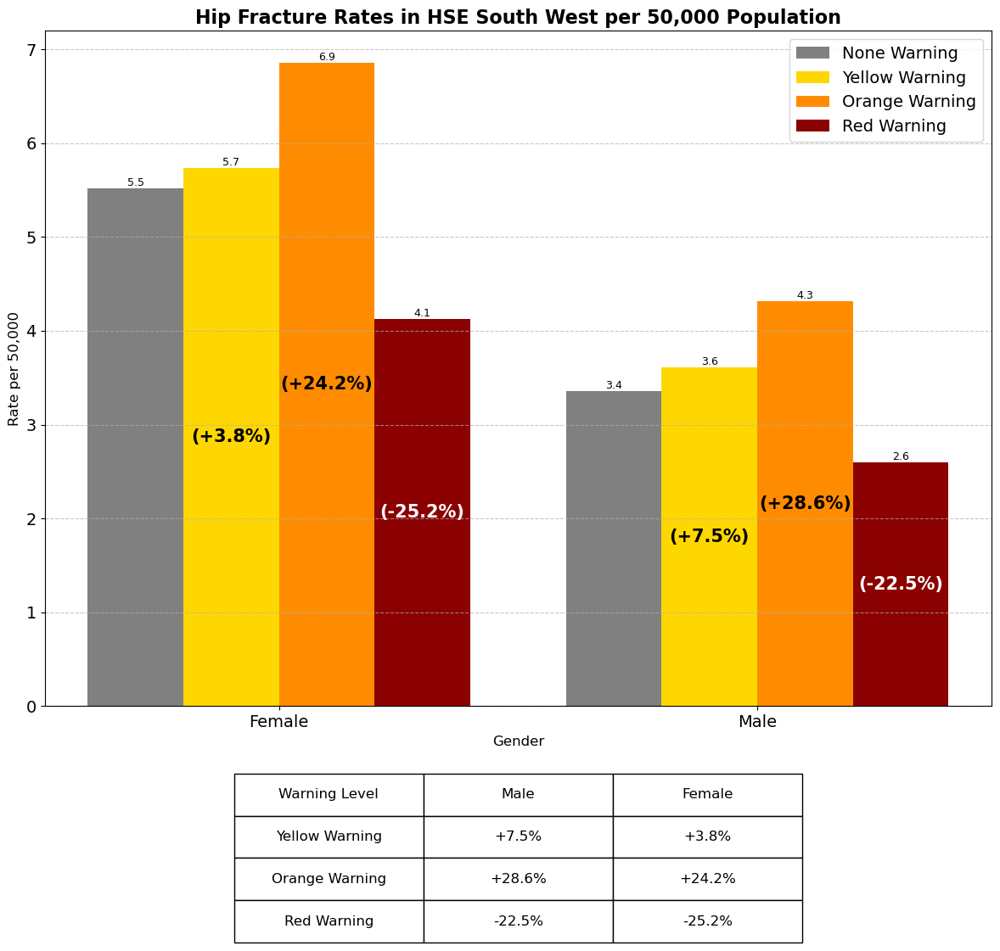

Plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_rates_HSE_West_and_North_West.png


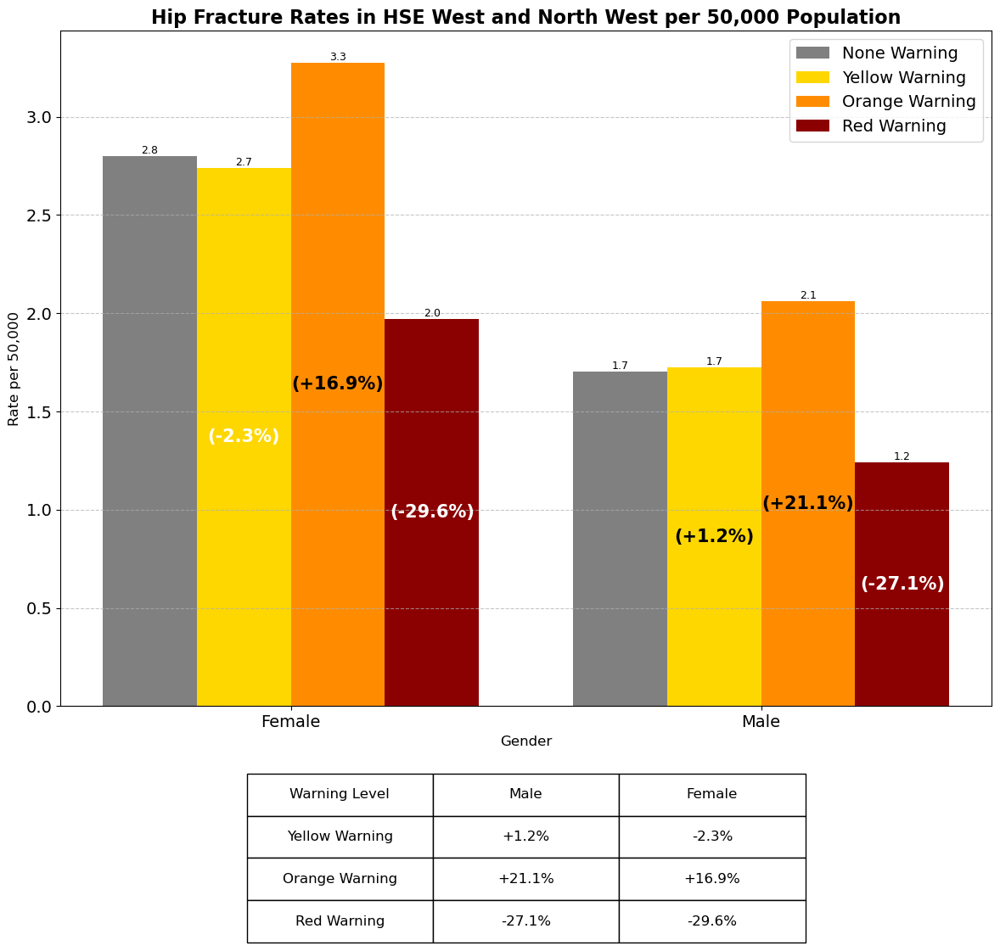

In [10]:
# Example usage:
rates = calculate_hip_fracture_rates(poisson_results_2, df_final_expanded, reference_population=50000)
plot_rates_by_region(rates, save_path='/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/')

reference_population=50000


In [11]:
def calculate_percentage_changes(rates_df, reference_population=50000):
    """
    Calculate percentage changes from baseline for all combinations in the rates DataFrame.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        Output from calculate_hip_fracture_rates function
    reference_population : int, optional (default=100000)
        Population size used for standardization
    
    Returns:
    --------
    dict
        Dictionary with (region, gender, warning) keys and percentage change values
    """
    pct_changes = {}
    rate_col = f'Rate per {reference_population:,}'
    
    # store all baseline rates
    baselines = {}
    for _, row in rates_df[rates_df['Warning Color'] == 'None'].iterrows():
        region = row['Region']
        gender = row['Gender']
        baselines[(region, gender)] = row[rate_col]
    
    # calculate percentage changes for all non-baseline scenarios
    for _, row in rates_df[rates_df['Warning Color'] != 'None'].iterrows():
        region = row['Region']
        gender = row['Gender']
        warning = row['Warning Color']
        current_rate = row[rate_col]
        
        # Get the baseline rate
        baseline_key = (region, gender)
        if baseline_key in baselines and baselines[baseline_key] > 0:
            baseline_rate = baselines[baseline_key]
            pct_change = ((current_rate - baseline_rate) / baseline_rate) * 100
            pct_changes[(region, gender, warning)] = pct_change
    
    return pct_changes

def plot_nationwide_rates(rates_df, pct_changes, reference_population=50000, save_path=None):
    """
    Create a consolidated plot showing hip fracture rates across all of Ireland,
    summarizing the data from all regions with clear separation between gender groups.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        Output from calculate_hip_fracture_rates function
    pct_changes : dict
        Dictionary with (region, gender, warning) keys and percentage change values
    reference_population : int, optional (default=100000)
        Population size used for standardization
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    None (displays plot)
    """
    # Check if we have data
    if rates_df.empty:
        print("No data available to plot.")
        return
    
    # colors for warning levels
    warning_colors = {
        'None': 'gray',
        'Yellow': 'gold',
        'Orange': 'darkorange',
        'Red': 'darkred'
    }
    
    # Create the figure
    fig, ax = plt.subplots(figsize=(16, 10))
    plt.title('Hip Fracture Rates Across Ireland by Gender and Weather Warning Level', 
              fontsize=15, fontweight='bold')
    
    # Extract unique genders and warning levels
    genders = sorted(rates_df['Gender'].unique())
    warning_levels = sorted(rates_df['Warning Color'].unique())
    
    # Calculate average rates for each gender and warning level combination
    summary_data = []
    for gender in genders:
        for warning in warning_levels:
            subset = rates_df[(rates_df['Gender'] == gender) & 
                             (rates_df['Warning Color'] == warning)]
            
            if not subset.empty:
                rate_col = f'Rate per {reference_population:,}'
                avg_rate = subset[rate_col].mean()
                
                # Calculate average percentage change if not baseline
                avg_pct_change = 0
                if warning != 'None':
                    pct_values = [pct_changes.get((region, gender, warning), 0) 
                                 for region in rates_df['Region'].unique()]
                    pct_values = [p for p in pct_values if p != 0]  # Filter out missing values
                    avg_pct_change = sum(pct_values) / len(pct_values) if pct_values else 0
                
                summary_data.append({
                    'Gender': gender,
                    'Warning Color': warning,
                    'Average Rate': avg_rate,
                    'Average Pct Change': avg_pct_change
                })
    
    # Convert to DataFrame for easier plotting
    summary_df = pd.DataFrame(summary_data)
    
    width = 0.18  
    group_gap = 0.8
    
    # Create positions for gender groups with a gap between them
    if len(genders) == 2:  
        # Position groups on either side of the center with a gap
        x = np.array([-group_gap/2, group_gap/2])
    else:
        x = np.arange(len(genders)) * (1 + group_gap/len(genders))
    
    # Create a mapping from gender to position
    gender_positions = {gender: pos for gender, pos in zip(genders, x)}
    
    # Plot bars for each warning level within each gender group
    for i, warning in enumerate(warning_levels):
        warning_data = summary_df[summary_df['Warning Color'] == warning]
        
        if not warning_data.empty:
            for gender in genders:
                gender_warning_data = warning_data[warning_data['Gender'] == gender]
                
                if not gender_warning_data.empty:
                    # Get the position for this gender
                    pos = gender_positions[gender]
                    
                    # Calculate the offset for this warning level
                    offset = (i - len(warning_levels)/2 + 0.5) * width
                    
                    # Get the rate for this combination
                    rate = gender_warning_data['Average Rate'].values[0]
                    
                    # Create the bar
                    bar = ax.bar(pos + offset, rate, width, 
                                 label=f'{warning} Warning' if gender == genders[0] else "",
                                 color=warning_colors[warning])
                    
                    # Add rate label on top
                    ax.text(pos + offset, rate, f'{rate:.1f}', 
                            ha='center', va='bottom', fontsize=12)
                    
                    # Add percentage change for non-baseline warning levels
                    if warning != 'None':
                        pct_change = gender_warning_data['Average Pct Change'].values[0]
                        ax.text(pos + offset, rate*0.5, f'({pct_change:+.1f}%)', 
                                ha='center', va='center', fontsize=12, fontweight='bold',
                                color='white' if pct_change < 0 else 'black')
    
    # Set up the x-axis with gender labels
    ax.set_xticks(list(gender_positions.values()))
    ax.set_xticklabels(list(gender_positions.keys()), fontsize=12)
    
    # Add vertical lines to separate gender groups more clearly
    if len(genders) > 1:
        gender_positions_list = list(gender_positions.values())
        for i in range(len(gender_positions_list) - 1):
            mid_point = (gender_positions_list[i] + gender_positions_list[i+1]) / 2
            ax.axvline(x=mid_point, color='lightgray', linestyle='--', alpha=0.5)
    
    # Add y-axis label and grid
    ax.set_ylabel(f'Rate per {reference_population:,}', fontsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add legend
    ax.legend(title='Warning Level', loc='upper right')
    
    table_data = []
    for warning in [w for w in warning_levels if w != 'None']:
        if len(genders) > 1:
            male_data = summary_df[(summary_df['Gender'] == 'Male') & (summary_df['Warning Color'] == warning)]
            female_data = summary_df[(summary_df['Gender'] == 'Female') & (summary_df['Warning Color'] == warning)]
        
            if not male_data.empty and not female_data.empty:
                male_pct = male_data['Average Pct Change'].values[0]
                female_pct = female_data['Average Pct Change'].values[0]
            
                table_data.append([f"{warning} Warning", f"{male_pct:+.1f}%", f"{female_pct:+.1f}%"])
    
    if table_data:
        # Add table at the bottom
        columns = ['Warning Level', 'Male', 'Female']
        table = plt.table(cellText=table_data,
                     colLabels=columns,
                     cellLoc='center',
                     loc='bottom',
                     bbox=[0.2, -0.4, 0.6, 0.3])
        table.auto_set_font_size(False)
        table.set_fontsize(12)
        table.scale(1, 1.5)
    
    plt.tight_layout(rect=[0, 0.15, 1, 0.98])
    
    # Save the plot if a path is provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Nationwide summary plot saved to: {save_path}")
    
    plt.show()

Nationwide summary plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/ireland_hip_fracture_summary.png


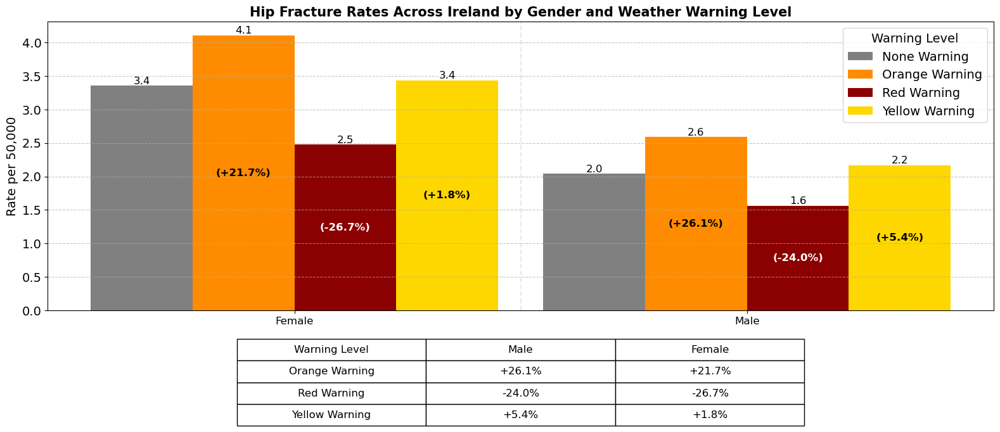

In [12]:
rates_df = calculate_hip_fracture_rates(poisson_results_2, df_final_expanded)
pct_changes = calculate_percentage_changes(rates_df)
# Create the nationwide plot with clear separation between gender groups
plot_nationwide_rates(rates_df, pct_changes, save_path="/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/ireland_hip_fracture_summary.png")

In [13]:
def plot_yearly_hip_fractures_by_weather(df, save_path=None):
    """
    Create a stacked bar chart showing total hip fractures per year and 
    how many happened during adverse weather conditions.
    
    Parameters:
    -----------
    df : pandas DataFrame
        Dataset with daily observations including dates, weather events, and hip fracture counts
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    pandas DataFrame
        Summary data of fractures by year and weather condition
    """
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np
    
    # Check if we have data
    if df.empty:
        print("No data available to plot.")
        return
    
    # Ensure the required columns
    required_cols = ['date', 'weather_event', 'hip_fracture_count']
    if not all(col in df.columns for col in required_cols):
        print(f"Error: Dataset must contain all of these columns: {required_cols}")
        return
    
    # Convert date column to datetime
    if not pd.api.types.is_datetime64_any_dtype(df['date']):
        df['date'] = pd.to_datetime(df['date'])
    
    # Extract year from date
    df['year'] = df['date'].dt.year
    
    # Group by year and calculate the metrics
    yearly_data = []
    
    for year in sorted(df['year'].unique()):
        year_df = df[df['year'] == year]
        
        # Calculate total fractures for the year
        total_fractures = year_df['hip_fracture_count'].sum()
        
        # Calculate fractures during adverse weather
        adverse_weather_fractures = year_df[year_df['weather_event'] > 0]['hip_fracture_count'].sum()
        
        # Calculate fractures during normal weather
        normal_weather_fractures = total_fractures - adverse_weather_fractures
        
        yearly_data.append({
            'Year': year,
            'Total Fractures': total_fractures,
            'Fractures During Adverse Weather': adverse_weather_fractures,
            'Fractures During Non Adverse Weather': normal_weather_fractures,
            'Percentage During Adverse Weather': (adverse_weather_fractures / total_fractures * 100) if total_fractures > 0 else 0
        })
    
    # Convert to DataFrame
    yearly_df = pd.DataFrame(yearly_data)
    
    # Create figure with appropriate dimensions
    fig, ax = plt.subplots(figsize=(11.5, 5.5))
    
    # Set up the x-axis values - use actual positions (0, 1, 2, etc.)
    x_pos = np.arange(len(yearly_df))
    
    # Get the data
    years = yearly_df['Year'].astype(str)  # Convert years to strings for display
    adverse_fractures = yearly_df['Fractures During Adverse Weather']
    normal_fractures = yearly_df['Fractures During Non Adverse Weather']
    
    # Create the stacked bars
    p1 = ax.bar(x_pos, adverse_fractures, width=0.7, color='Red', label='During Adverse Weather')
    p2 = ax.bar(x_pos, normal_fractures, width=0.7, bottom=adverse_fractures, color='darkorange', label='During No Weather')
    
    # Add labels and title
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel('Number of Hip Fractures', fontsize=12)
    ax.set_title('Total Hip Fractures by Year and Weather Condition', fontsize=16)
    
    # Set x-ticks to be at the positons and label them with the years
    ax.set_xticks(x_pos)
    ax.set_xticklabels(years, rotation=0)  # No rotation for years
    
    # Add spacing to prevent crowding - adjust the x-axis limits
    plt.xlim(-0.5, len(yearly_df) - 0.5)
    
    # Add legend
    ax.legend(loc='upper left')
    
    # Add a grid for easier reading
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add annotations with appropriate spacing
    for i, year_data in enumerate(yearly_data):
        total = year_data['Total Fractures']
        adverse = year_data['Fractures During Adverse Weather']
        percentage = year_data['Percentage During Adverse Weather']
        
        # Add total number at the top of each bar with some padding
        ax.text(i, total + (max(yearly_df['Total Fractures']) * 0.02), 
                f'Total: {int(total)}', ha='center', va='bottom', fontsize=10)
        
        # Add percentage in the middle of the adverse weather portion
        # Only if the section is large enough to fit text
        if adverse > max(yearly_df['Total Fractures']) * 0.05:
            ax.text(i, adverse/2, f'{percentage:.1f}%', 
                    ha='center', va='center', color='black', fontweight='bold', fontsize=10)
    
    # Ensure there's enough room at the top for labels
    max_value = yearly_df['Total Fractures'].max()
    ax.set_ylim(0, max_value * 1.1)  # Add 10% padding at the top
    
    # Use tight layout to optimize use of space
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Yearly hip fractures plot saved to: {save_path}")
        
    plt.show()
    
    return yearly_df  # Return the aggregated data for further analysis

Yearly hip fractures plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/yearly_hip_fractures.png


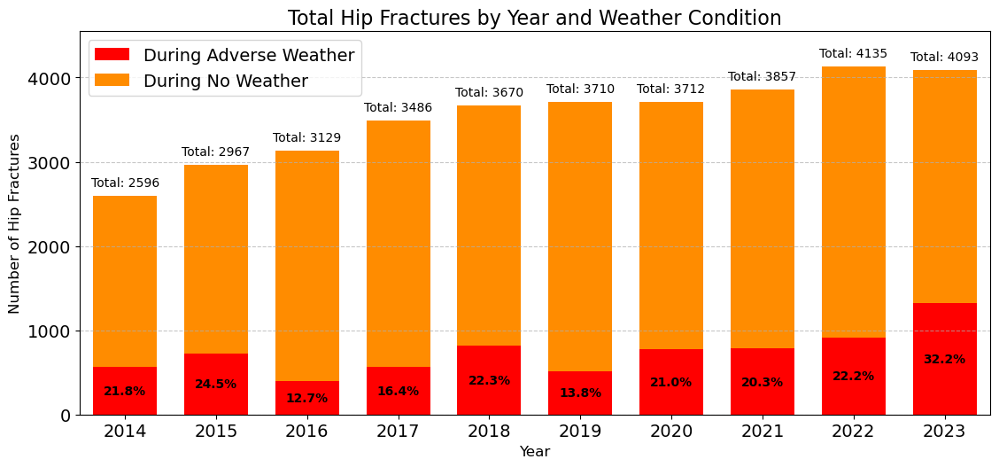

In [14]:
# Assuming 'df' contains your dataset with the required columns
yearly_summary = plot_yearly_hip_fractures_by_weather(df_final_expanded, save_path="/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/yearly_hip_fractures.png")

In [15]:
def plot_hip_fractures_by_age_gender_weather(df, save_path=None):
    """
    Create a stacked bar chart showing the percentage distribution of hip fractures
    by age group, gender, and weather conditions across all years, using a 
    colorblind-friendly palette from ColorBrewer. Simplified labels for clarity.
    
    Parameters:
    -----------
    df : pandas DataFrame
        Dataset with hip fracture information including age_group, gender, weather_event, and hip_fracture_count
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    pandas DataFrame
        Summary of hip fracture percentages by age group, gender, and weather condition
    """
    # Ensure required columns
    required_cols = ['age_group', 'gender', 'hip_fracture_count', 'weather_event']
    if not all(col in df.columns for col in required_cols):
        print(f"Error: Dataset must contain all of these columns: {required_cols}")
        return
    
    # Process the age group labels - change "85 years and over" to "85+" - take sup too much room 
    df = df.copy()
    df['age_group'] = df['age_group'].replace('85 years and over', '85+')
    
    # Calculate total fractures by age group, gender, and weather
    age_gender_weather_counts = df.groupby(['age_group', 'gender', 'weather_event'])['hip_fracture_count'].sum().reset_index()
    
    # Calculate total fractures overall
    total_fractures = age_gender_weather_counts['hip_fracture_count'].sum()
    
    # Calculate percentages of total fractures
    age_gender_weather_counts['percentage'] = (age_gender_weather_counts['hip_fracture_count'] / total_fractures) * 100
    
    # Order age groups appropriately 
    age_groups = sorted(age_gender_weather_counts['age_group'].unique(), 
                         key=lambda x: int(x.split('-')[0]) if '-' in x else 
                                      (int(x.split('+')[0]) if '+' in x else 
                                       (int(x.split(' ')[0]) if x[0].isdigit() else 100)))
    
    color_mapping = {
        ('Female', 0.0): '#FED976',  # Light yellow for females in normal weather
        ('Female', 1.0): '#E31A1C',  # Dark red for females in adverse weather
        ('Male', 0.0): '#FEB24C',    # Light orange for males in normal weather
        ('Male', 1.0): '#BD0026'     # Darker red for males in adverse weather
    }
    
    # Create figure with more space for layout
    fig = plt.figure(figsize=(14, 14))  
    
    # Add the main chart in the top subplot
    ax1 = plt.subplot2grid((12, 1), (0, 0), rowspan=8)
    
    # Set up the grouped bar chart
    bar_width = 0.4
    index = np.arange(len(age_groups))
    
    pivot_data = age_gender_weather_counts.pivot_table(
        index=['age_group', 'gender'], 
        columns=['weather_event'], 
        values=['hip_fracture_count', 'percentage']
    ).fillna(0)
    
    # Create empty lists
    female_normal_pcts = []
    female_adverse_pcts = []
    male_normal_pcts = []
    male_adverse_pcts = []
    
    # Populate data for each age group
    for age in age_groups:
        # Female data
        try:
            f_normal = pivot_data.loc[(age, 'Female'), ('percentage', 0.0)]
            female_normal_pcts.append(f_normal)
        except KeyError:
            female_normal_pcts.append(0)
            
        try:
            f_adverse = pivot_data.loc[(age, 'Female'), ('percentage', 1.0)]
            female_adverse_pcts.append(f_adverse)
        except KeyError:
            female_adverse_pcts.append(0)
            
        # Male data
        try:
            m_normal = pivot_data.loc[(age, 'Male'), ('percentage', 0.0)]
            male_normal_pcts.append(m_normal)
        except KeyError:
            male_normal_pcts.append(0)
            
        try:
            m_adverse = pivot_data.loc[(age, 'Male'), ('percentage', 1.0)]
            male_adverse_pcts.append(m_adverse)
        except KeyError:
            male_adverse_pcts.append(0)
    
    # Plot the stacked bars
    # Female bars
    female_normal_bars = ax1.bar(index - bar_width/2, female_normal_pcts, bar_width, 
            color=color_mapping[('Female', 0.0)], edgecolor='black', linewidth=0.5)
    female_adverse_bars = ax1.bar(index - bar_width/2, female_adverse_pcts, bar_width, 
            bottom=female_normal_pcts, color=color_mapping[('Female', 1.0)], 
            edgecolor='black', linewidth=0.5)
    
    # Male bars
    male_normal_bars = ax1.bar(index + bar_width/2, male_normal_pcts, bar_width, 
            color=color_mapping[('Male', 0.0)], edgecolor='black', linewidth=0.5)
    male_adverse_bars = ax1.bar(index + bar_width/2, male_adverse_pcts, bar_width, 
            bottom=male_normal_pcts, color=color_mapping[('Male', 1.0)], 
            edgecolor='black', linewidth=0.5)
    
    # Add labels, title, and legend
    ax1.set_xlabel('Age Group', fontsize=14)
    ax1.set_ylabel('Percentage of Total Hip Fractures (%)', fontsize=14)
    ax1.set_title('Distribution of Hip Fractures by Age Group, Gender, and Weather Condition (2014-2023)', fontsize=16)
    ax1.set_xticks(index)
    ax1.set_xticklabels(age_groups, rotation=45, ha='right', fontsize=12)
    ax1.tick_params(axis='x', pad=10)  # Add padding below x-axis labels
    
    # Custom legend 
    legend_elements = [
        Patch(facecolor=color_mapping[('Female', 0.0)], edgecolor='black', label='Female - Normal Weather'),
        Patch(facecolor=color_mapping[('Female', 1.0)], edgecolor='black', label='Female - Adverse Weather'),
        Patch(facecolor=color_mapping[('Male', 0.0)], edgecolor='black', label='Male - Normal Weather'),
        Patch(facecolor=color_mapping[('Male', 1.0)], edgecolor='black', label='Male - Adverse Weather')
    ]
    ax1.legend(handles=legend_elements, loc='upper left', fontsize=12)
    
    # Add grid for better readability
    ax1.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add percentage labels on top of each bar
    for i in range(len(age_groups)):
        # Calculate total percentages for each gender
        female_total = female_normal_pcts[i] + female_adverse_pcts[i]
        male_total = male_normal_pcts[i] + male_adverse_pcts[i]
        
        # Add total percentage labels if bars are high enough
        if female_total > 0.5:
            ax1.text(i - bar_width/2, female_total + 0.3, f'{female_total:.1f}%', 
                    ha='center', va='bottom', fontsize=10)
        
        if male_total > 0.5:
            ax1.text(i + bar_width/2, male_total + 0.3, f'{male_total:.1f}%', 
                    ha='center', va='bottom', fontsize=10)
        
        # Add percentage breakdown for adverse weather if high enough
        if female_adverse_pcts[i] > 0.5:
            ax1.text(i - bar_width/2, female_normal_pcts[i] + female_adverse_pcts[i]/2, 
                    f'{female_adverse_pcts[i]/female_total*100:.0f}%', 
                    ha='center', va='center', color='white', fontsize=9, fontweight='bold')
            
        if male_adverse_pcts[i] > 0.5:
            ax1.text(i + bar_width/2, male_normal_pcts[i] + male_adverse_pcts[i]/2, 
                    f'{male_adverse_pcts[i]/male_total*100:.0f}%', 
                    ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    
    # Calculate totals by weather and gender for annotations
    weather_gender_totals = age_gender_weather_counts.groupby(['gender', 'weather_event'])['hip_fracture_count'].sum()
    
    female_normal = weather_gender_totals.get(('Female', 0.0), 0)
    female_adverse = weather_gender_totals.get(('Female', 1.0), 0)
    male_normal = weather_gender_totals.get(('Male', 0.0), 0)
    male_adverse = weather_gender_totals.get(('Male', 1.0), 0)
    
    female_total = female_normal + female_adverse
    male_total = male_normal + male_adverse
    total_fractures = female_total + male_total
    
    plt.tight_layout(h_pad=3.0)
    plt.subplots_adjust(hspace=0.4)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Hip fracture demographics plot saved to: {save_path}")
    
    plt.show()
    


/tmp/ipykernel_60904/381595844.py:174: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout(h_pad=3.0)


Hip fracture demographics plot saved to: /home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_demographics_weather.png


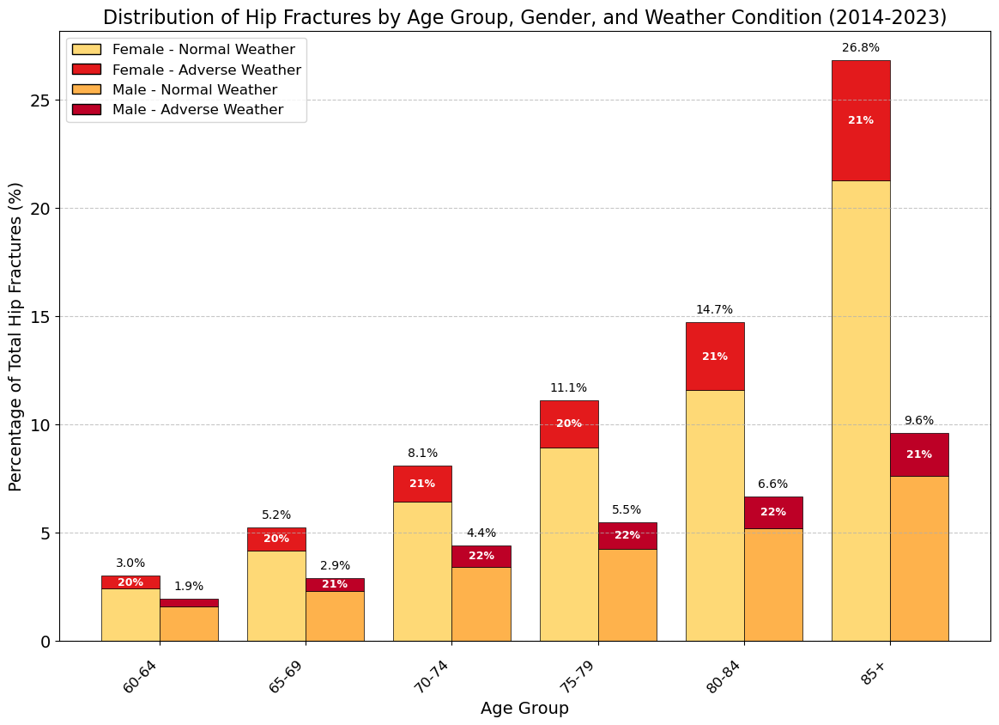

In [16]:
plot_hip_fractures_by_age_gender_weather(df_final_expanded, save_path="/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/hip_fracture_demographics_weather.png")


Correlations with hip_fracture_count:
hip_fracture_count          1.000000
female                      0.344067
male                        0.241170
orange_warning              0.020927
warning_severity_numeric    0.014164
weather_event               0.013177
yellow_warning              0.006588
red_warning                -0.013222
Name: hip_fracture_count, dtype: float64


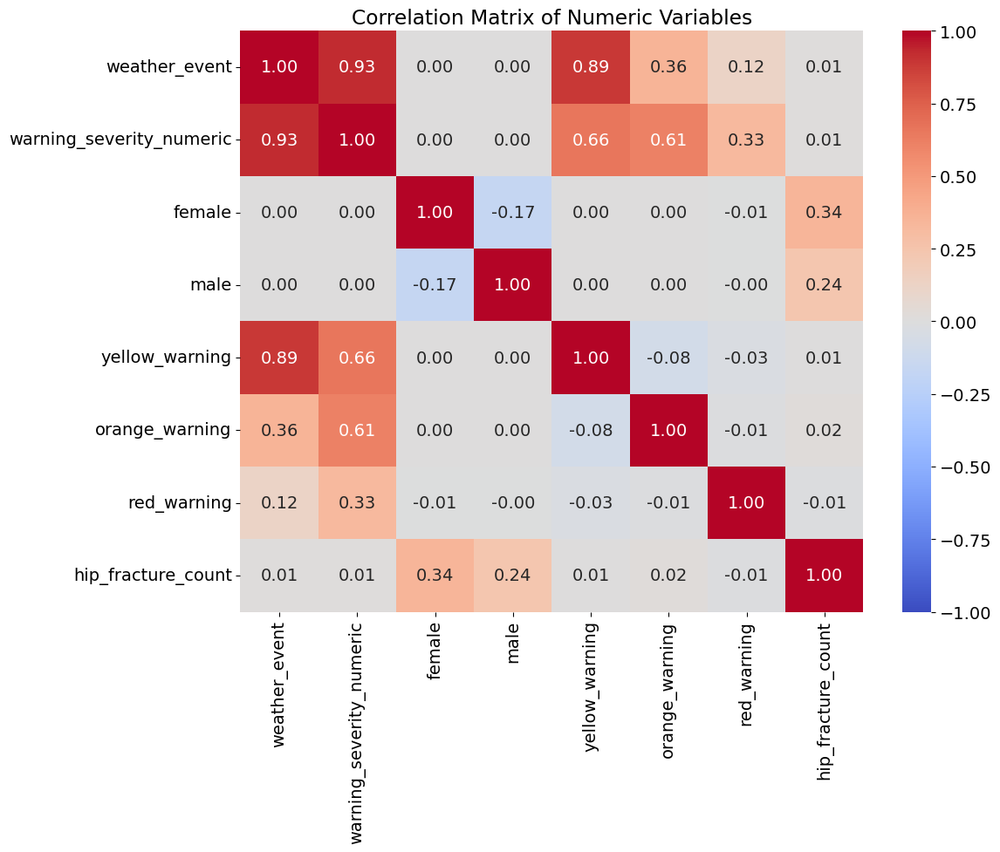

In [17]:
numeric_cols = ['weather_event', 'warning_severity_numeric', 'female', 'male', 'yellow_warning','orange_warning','red_warning','hip_fracture_count']
save_path="/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/heatmap.png"

if 'hip_fracture_count' not in numeric_cols:
    print("Warning: hip_fracture_count not found in numeric columns")
else:
    # Create a correlation matrix
    corr_matrix = df_final_expanded[numeric_cols].corr(method='pearson')
    
    # Sort correlations with hip_fracture_count
    hip_correlations = corr_matrix['hip_fracture_count'].sort_values(ascending=False)
    print("Correlations with hip_fracture_count:")
    print(hip_correlations)
    
    # Plot heatmap of correlations
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
    plt.title('Correlation Matrix of Numeric Variables')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    

In [18]:
def calculate_percentage_changes(rates_df, reference_population=50000):
    """
    Calculate percentage changes from baseline for all combinations in the rates DataFrame.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        Output from calculate_hip_fracture_rates function
    reference_population : int, optional (default=100000)
        Population size used for standardization
    
    Returns:
    --------
    dict
        Dictionary with (region, gender, warning) keys and percentage change values
    """
    pct_changes = {}
    rate_col = f'Rate per {reference_population:,}'
    
    # First, store all baseline rates
    baselines = {}
    for _, row in rates_df[rates_df['Warning Color'] == 'None'].iterrows():
        region = row['Region']
        gender = row['Gender']
        baselines[(region, gender)] = row[rate_col]
    
    # Then calculate percentage changes for all non-baseline scenarios
    for _, row in rates_df[rates_df['Warning Color'] != 'None'].iterrows():
        region = row['Region']
        gender = row['Gender']
        warning = row['Warning Color']
        current_rate = row[rate_col]
        
        # Get the corresponding baseline rate
        baseline_key = (region, gender)
        if baseline_key in baselines and baselines[baseline_key] > 0:
            baseline_rate = baselines[baseline_key]
            pct_change = ((current_rate - baseline_rate) / baseline_rate) * 100
            pct_changes[(region, gender, warning)] = pct_change
    
    return pct_changes

In [19]:
# Set the renderer to notebook for Jupyter
pio.renderers.default = "notebook"

def plot_hip_fracture_sunburst(rates_df, pct_changes, reference_population=50000, save_path=None):
    """
    Create a sunburst visualization showing hip fracture rates
    for all regions by gender during different weather warning levels.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        DataFrame with columns 'Region', 'Gender', 'Warning Color', and rate column
    pct_changes : dict
        Dictionary with (region, gender, warning) keys and percentage change values
    reference_population : int, optional (default=50000)
        Population size used for standardization
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    plotly figure
    """
    if rates_df.empty:
        print("No data available to plot.")
        return None
    
    # Define colors for warning levels
    warning_colors = {
        'None': '#8B8B8B',   # Gray
        'Yellow': '#FFD700', # Gold
        'Orange': '#FF8C00', # Dark Orange
        'Red': '#B22222'     # Firebrick Red
    }
    
    # Gender colors
    gender_colors = {
        'Female': '#E377C2',  # Pink
        'Male': '#1F77B4'     # Blue
    }
    
    # Get unique regions and genders
    regions = sorted(rates_df['Region'].unique())
    genders = sorted(rates_df['Gender'].unique())
    
    # Rate column name
    rate_col = f'Rate per {reference_population:,}'
    
    # Prepare data for sunburst chart
    labels = []
    parents = []
    values = []  # We'll use this for the rates
    colors = []  # For custom coloring
    customdata = []  # For percentage changes
    
    # Add root
    labels.append("Hip Fractures")
    parents.append("")
    values.append(0)  
    colors.append("white")
    customdata.append([0, ""])
    
    # Add regions
    for region in regions:
        region_data = rates_df[rates_df['Region'] == region]
        region_avg_rate = region_data[rate_col].mean() if not region_data.empty else 0
        
        labels.append(region)
        parents.append("Hip Fractures")
        values.append(region_avg_rate)
        colors.append("#AAAAAA") 
        customdata.append([0, f"Average rate: {region_avg_rate:.1f}"])
        
        # Add genders for each region
        for gender in genders:
            gender_data = region_data[region_data['Gender'] == gender]
            if not gender_data.empty:
                gender_avg_rate = gender_data[rate_col].mean()
                
                labels.append(f"{region} - {gender}")
                parents.append(region)
                values.append(gender_avg_rate)
                colors.append(gender_colors[gender])
                customdata.append([0, f"Average rate: {gender_avg_rate:.1f}"])
                
                # Add warning levels for each region and gender
                for warning in warning_colors.keys():
                    warning_data = gender_data[gender_data['Warning Color'] == warning]
                    
                    if not warning_data.empty:
                        avg_rate = warning_data[rate_col].mean()
                        # Get percentage change using the correct key structure
                        pct_change = pct_changes.get((region, gender, warning), 0)
                        
                        labels.append(f"{region} - {gender} - {warning}")
                        parents.append(f"{region} - {gender}")
                        values.append(avg_rate)
                        colors.append(warning_colors[warning])
                        customdata.append([pct_change, f"Rate: {avg_rate:.1f}<br>Change: {pct_change:+.1f}%"])
    
    # Create the sunburst figure
    fig = go.Figure(go.Sunburst(
        labels=labels,
        parents=parents,
        values=values,
        branchvalues="total",
        marker=dict(colors=colors),
        customdata=customdata,
        hovertemplate='<b>%{label}</b><br>%{customdata[1]}<extra></extra>',
        maxdepth=3  # Limit to region, gender, and warning level
    ))
    
    # Update layout
    fig.update_layout(
        title={
            'text': 'Hip Fracture Rates by Region, Gender, and Weather Warning Level',
            'font': {'size': 24, 'family': 'Arial, sans-serif', 'color': 'black'},
            'x': 0.5,
            'xanchor': 'center'
        },
        width=900,
        height=900,
        margin=dict(t=100, l=0, r=0, b=0)
    )
    
    # Save if requested
    if save_path:
        fig.write_image(save_path)
        print(f"Sunburst visualization saved to: {save_path}")
    
    return fig

def plot_hip_fracture_sunburst_simplified(rates_df, pct_changes, reference_population=50000, save_path=None):
    """
    Create a simplified sunburst visualization focusing only on regions and warning levels,
    averaging across genders to make the visualization less complex.
    
    Parameters:
    -----------
    rates_df : pandas DataFrame
        DataFrame with columns 'Region', 'Gender', 'Warning Color', and rate column
    pct_changes : dict
        Dictionary with (region, gender, warning) keys and percentage change values
    reference_population : int, optional (default=50000)
        Population size used for standardization
    save_path : str or None, optional (default=None)
        If provided, saves the plot to this file path
    
    Returns:
    --------
    plotly figure
    """
    # Check if we have any data to plot
    if rates_df.empty:
        print("No data available to plot.")
        return None
    
    # Define colors for warning levels
    warning_colors = {
        'None': '#8B8B8B',   # Gray
        'Yellow': '#FFD700', # Gold
        'Orange': '#FF8C00', # Dark Orange
        'Red': '#B22222'     # Firebrick Red
    }
    
    # Get unique regions
    regions = sorted(rates_df['Region'].unique())
    
    # Rate column name
    rate_col = f'Rate per {reference_population:,}'
    
    # Prepare data for sunburst chart
    labels = []
    parents = []
    values = [] 
    colors = [] 
    customdata = [] 
    
    # Add root
    labels.append("Hip Fractures")
    parents.append("")
    values.append(0) 
    colors.append("white")
    customdata.append([0, ""])  
    
    avg_rates = rates_df.groupby(['Region', 'Warning Color'])[rate_col].mean().reset_index()
    
    # Calculate average percentage changes
    avg_pct_changes = {}
    for region in regions:
        for warning in warning_colors.keys():
            # Find all keys for this region and warning
            relevant_keys = [k for k in pct_changes.keys() 
                            if k[0] == region and k[2] == warning]
            if relevant_keys:
                # Calculate average percentage change
                avg_pct = sum(pct_changes[k] for k in relevant_keys) / len(relevant_keys)
                avg_pct_changes[(region, warning)] = avg_pct
    
    # Add regions
    for region in regions:
        region_data = avg_rates[avg_rates['Region'] == region]
        region_avg_rate = region_data[rate_col].mean() if not region_data.empty else 0
        
        labels.append(region)
        parents.append("Hip Fractures")
        values.append(region_avg_rate)
        colors.append("#AAAAAA") 
        customdata.append([0, f"Average rate: {region_avg_rate:.1f}"])
        
        # Add warning levels for each region 
        for warning in warning_colors.keys():
            warning_data = region_data[region_data['Warning Color'] == warning]
            
            if not warning_data.empty:
                avg_rate = warning_data[rate_col].values[0]
                # Get percentage change using the simplified key structure
                pct_change = avg_pct_changes.get((region, warning), 0)
                
                labels.append(f"{region} - {warning}")
                parents.append(region)
                values.append(avg_rate)
                colors.append(warning_colors[warning])
                customdata.append([pct_change, f"Rate: {avg_rate:.1f}<br>Change: {pct_change:+.1f}%"])
    
    # Create the sunburst figure
    fig = go.Figure(go.Sunburst(
        labels=labels,
        parents=parents,
        values=values,
        branchvalues="total",
        marker=dict(colors=colors),
        customdata=customdata,
        hovertemplate='<b>%{label}</b><br>%{customdata[1]}<extra></extra>',
        maxdepth=2  # Limit to region and warning level
    ))
    
    # Update layout
    fig.update_layout(
        title={
            'text': 'Hip Fracture Rates by Region and Weather Warning Level (Averaged across Genders)',
            'font': {'size': 24, 'family': 'Arial, sans-serif', 'color': 'black'},
            'x': 0.5,
            'xanchor': 'center'
        },
        width=900,
        height=900,
        margin=dict(t=100, l=0, r=0, b=0)
    )
    
    # Add a legend for warning colors
    for i, (warning, color) in enumerate(warning_colors.items()):
        fig.add_annotation(
            x=0.95,
            y=0.9 - (i * 0.05),
            xref="paper",
            yref="paper",
            text=f"{warning} Warning",
            showarrow=False,
            font=dict(color="black", size=12),
            bgcolor=color,
            bordercolor="black",
            borderwidth=1,
            borderpad=4,
            opacity=0.8
        )
    
    # Save if requested
    if save_path:
        fig.write_image(save_path)
        print(f"Simplified sunburst visualization saved to: {save_path}")
    
    return fig

In [20]:
# Add these diagnostic checks before creating the plots
print("Rates dataframe shape:", rates_df.shape)
print("Rates dataframe columns:", rates_df.columns.tolist())
print("Sample of rates dataframe:\n", rates_df.head())
print("Warning colors present:", rates_df['Warning Color'].unique())
print("Number of regions:", rates_df['Region'].nunique())
print("Sample of pct_changes:", list(pct_changes.items())[:5])

Rates dataframe shape: (48, 5)
Rates dataframe columns: ['Region', 'Gender', 'Warning Color', 'Scenario', 'Rate per 50,000']
Sample of rates dataframe:
                     Region  Gender Warning Color        Scenario  \
0  HSE Dublin and Midlands  Female          None        Baseline   
2  HSE Dublin and Midlands  Female        Orange  Orange Warning   
3  HSE Dublin and Midlands  Female           Red     Red Warning   
1  HSE Dublin and Midlands  Female        Yellow  Yellow Warning   
4  HSE Dublin and Midlands    Male          None        Baseline   

   Rate per 50,000  
0         2.156995  
2         2.603044  
3         1.568496  
1         2.176698  
4         1.311340  
Warning colors present: ['None' 'Orange' 'Red' 'Yellow']
Number of regions: 6
Sample of pct_changes: [(('HSE Dublin and Midlands', 'Female', 'Orange'), 20.67922521406844), (('HSE Dublin and Midlands', 'Female', 'Red'), -27.283276629715118), (('HSE Dublin and Midlands', 'Female', 'Yellow'), 0.9134585260183006), 

In [21]:
def calculate_warning_distribution(df):
    """
    Calculate the distribution of weather warnings by region and severity.
    
    Parameters:
    -----------
    df : pandas DataFrame
        Dataset containing weather events and warnings
        
    Returns:
    --------
    pandas DataFrame
        Distribution of warnings by region and color
    """
    # create a mapping between warning_severity_numeric and colors
    severity_to_color = {
        0: "None",
        1: "Yellow",
        2: "Orange", 
        3: "Red"
    }
    
    # Add warning color column
    if 'warning_color' not in df.columns:
        df['warning_color'] = df['warning_severity_numeric'].map(severity_to_color)
    
    # Filter for days with weather events
    weather_events = df[df['weather_event'] == 1].copy()
    
    # Count warnings by region and color
    warning_counts = weather_events.groupby(['region', 'warning_color']).size().reset_index(name='count')
    
    # Calculate percentages within each region
    region_totals = warning_counts.groupby('region')['count'].sum().reset_index(name='total')
    warning_counts = warning_counts.merge(region_totals, on='region')
    warning_counts['percentage'] = (warning_counts['count'] / warning_counts['total'] * 100).round(1)
    
    # Add average severity per region
    avg_severity = weather_events.groupby('region')['warning_severity_numeric'].mean().reset_index()
    avg_severity = avg_severity.rename(columns={'warning_severity_numeric': 'avg_severity'})
    
    # Merge with region totals
    region_summary = region_totals.merge(avg_severity, on='region')
    
    return warning_counts, region_summary

In [22]:
calculate_warning_distribution(df_final_expanded)

(                       region warning_color  count  total  percentage
 0     HSE Dublin and Midlands        Orange    467   3104        15.0
 1     HSE Dublin and Midlands           Red     16   3104         0.5
 2     HSE Dublin and Midlands        Yellow   2621   3104        84.4
 3   HSE Dublin and North East        Orange    348   2253        15.4
 4   HSE Dublin and North East           Red     34   2253         1.5
 5   HSE Dublin and North East        Yellow   1871   2253        83.0
 6   HSE Dublin and South East        Orange    339   2532        13.4
 7   HSE Dublin and South East           Red     29   2532         1.1
 8   HSE Dublin and South East        Yellow   2164   2532        85.5
 9                HSE Mid West        Orange    706   4611        15.3
 10               HSE Mid West           Red    128   4611         2.8
 11               HSE Mid West        Yellow   3777   4611        81.9
 12             HSE South West        Orange    586   3553        16.5
 13   

In [23]:
warning_counts, region_summary = calculate_warning_distribution(df_final_expanded)
rates_df = calculate_hip_fracture_rates(poisson_results_2, df_final_expanded)
pct_changes = calculate_percentage_changes(rates_df)

In [24]:
!pip install -U kaleido

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


In [25]:
import plotly.io as pio
# Okabe–Ito subset for warnings:
warning_colors = {
    'None': '#bdbdbd',    # Medium gray (from Greys)
    'Yellow': '#ffffb2',  # Light yellow (YlOrRd)
    'Orange': '#feb24c',  # Mid orange (YlOrRd)
    'Red': '#f03b20'      # Deep red (YlOrRd)
}

# Okabe–Ito subset for gender:
gender_color_map = {
    'Male': '#66c2a5',    # Teal-ish from Set2
    'Female': '#fc8d62'   # Salmon from Set2
}

# For region colors, you can also pick from Okabe–Ito or other color-blind safe sets:
region_colors = [
    '#1b9e77',  # Teal
    '#d95f02',  # Dark orange
    '#7570b3',  # Muted purple
    '#e7298a',  # Magenta/pink
    '#66a61e',  # Green
    '#e6ab02'   # Mustard
]

center_color = "#8da0cb"  # A soft purple-blue from Set2
##############################################
# SECTION 2: DATA STRUCTURE SETUP
##############################################
# These lists will hold all data for the sunburst chart
ids = []       # Unique ID for each node/circle
labels = []    # Text that appears on each circle
parents = []   # Parent circle ID (determines hierarchy)
values = []    # Numeric value for sizing circles
colors = []    # Fill color for each circle
customdata = []  # Extra data shown on hover
##############################################
# SECTION 3: (CENTER CIRCLE)
##############################################
# Create the center circle of the sunburst chart
root_id = "WEATHERED"
ids.append(root_id)
labels.append(root_id)  # This text appears in the center
parents.append("")  # No parent for the root node
root_value = rates_df['Rate per 50,000'].sum()  # Keep original size
values.append(root_value)
colors.append(center_color)  # Using the transparent center color
customdata.append("")
##############################################
# SECTION 4: REGION NODES (FIRST CIRCLE LAYER)
##############################################
# Create the first layer of circles (Regions)
region_index = 0 
for region in sorted(rates_df['Region'].unique()):
    # --- Process region names to remove HSE and add line breaks ---
    clean_region = region.replace("HSE ", "").replace("HSE", "").strip()
    
    # Add line breaks for region labels to make them appear level
    if len(clean_region) > 12:
        words = clean_region.split()
        wrapped_region = ""
        line_length = 0
        
        for word in words:
            if line_length + len(word) > 12:
                wrapped_region += "<br>" + word  # <br> creates a line break in the label
                line_length = len(word)
            else:
                if wrapped_region:
                    wrapped_region += " " + word
                else:
                    wrapped_region = word
                line_length += len(word) + 1
        
        display_region = wrapped_region
    else:
        display_region = clean_region
    
    # --- Add this region to our data structure ---
    region_id = f"Region: {region}"
    
    # Add black bold text for region labels using HTML styling
    region_display = f"<span style='color: black; font-weight: bold;'>{display_region}</span>"
    
    ids.append(region_id)
    labels.append(region_display)  # White text on region circles
    parents.append(root_id)  # Connect to the center circle
    region_value = rates_df.loc[rates_df['Region'] == region, 'Rate per 50,000'].sum()
    values.append(region_value)  # Size of this region's circle
    
    # Select one color from our region_colors array based on the current index
    region_color = region_colors[region_index % len(region_colors)]
    colors.append(region_color)  # Add just this one color to the colors array
    
    customdata.append(f"Region: {clean_region}")  # Hover text for this region
    region_index += 1  # Increase the index for the next region
    
    ##############################################
    # SECTION 5: WARNING NODES (NOW MIDDLE CIRCLE LAYER)
    ##############################################
    
    # Create the middle layer of circles (Warning levels under each region)
    for warning in sorted(rates_df[(rates_df['Region'] == region)]['Warning Color'].unique()):
        warning_id = f"{region_id} - {warning}"
        
        # Initialize warning display as empty
        warning_display = ""
        
        # Only find and display percentages for Red, Orange, and Yellow warnings
        if warning in ["Red", "Orange", "Yellow"]:
            # Find the percentage of this warning type in this region
            warning_pct = 0
            warning_row = warning_counts[(warning_counts['region'] == region) & 
                                      (warning_counts['warning_color'] == warning)]
            if not warning_row.empty:
                warning_pct = warning_row['percentage'].iloc[0]
            
            # Adjust text color based on warning color for better contrast
            text_color = "black"  # Default text color
            if warning in ['Red', 'Orange']:  # Darker backgrounds
                text_color = "white"  # Use white text for better visibility
                
            # Create the warning label with just the percentage
            warning_display = f"<span style='color: black; font-weight: bold;'>{warning_pct:.1f}%</span>"
        
        ids.append(warning_id)
        labels.append(warning_display)  
        parents.append(region_id) 
        
        # Calculate the sum of rates for this region and warning level - keep the original sizing
        warning_value = rates_df.loc[(rates_df['Region'] == region) & 
                                   (rates_df['Warning Color'] == warning), 'Rate per 50,000'].sum()
        values.append(warning_value)  
        
        # Use the appropriate warning color
        colors.append(warning_colors.get(warning, "gray"))
        
        # Include frequency percentage in customdata only for colored warnings
        if warning in ["Red", "Orange", "Yellow"]:
            customdata.append(f"Region: {clean_region}<br>Warning: {warning}<br>Frequency: {warning_pct:.1f}%")
        else:
            customdata.append(f"Region: {clean_region}<br>Warning: {warning}")
            
    
        
        ##############################################
        # SECTION 6: GENDER NODES (NOW OUTER CIRCLE LAYER)
        ##############################################
        
        # Create the outer layer of circles (Gender segments under each warning level)
        for gender in sorted(rates_df[(rates_df['Region'] == region) & 
                                     (rates_df['Warning Color'] == warning)]['Gender'].unique()):
            # Only proceed if there's data for this combination
            sub_df = rates_df[(rates_df['Region'] == region) & 
                             (rates_df['Warning Color'] == warning) & 
                             (rates_df['Gender'] == gender)]
            
            if not sub_df.empty:
                gender_id = f"{warning_id} - {gender}"
                
                # Get the rate value
                rate = sub_df['Rate per 50,000'].iloc[0]
                pct = pct_changes.get((region, gender, warning), 0)
                
                # Format the gender display with only rate information (no gender label)
                if pct != 0:
                    gender_label = f"{rate:.1f}<br>{pct:+.1f}%"
                else:
                    gender_label = f"{rate:.1f}"
                
                # Add white bold text for gender labels
                gender_display = f"<span style='color: black; font-weight: bold;'>{gender_label}</span>"
                
                ids.append(gender_id)
                labels.append(gender_display)
                parents.append(warning_id)  # Connect to the warning level circle
                values.append(rate)
                colors.append(gender_color_map.get(gender, "gray"))
                
                # Detailed hover information
                customdata.append(f"Region: {clean_region}<br>Warning: {warning}<br>Gender: {gender}<br>Rate: {rate:.1f}<br>Change: {pct:+.1f}%")
##############################################
# SECTION 7: CREATING THE SUNBURST CHART
##############################################
# Create the sunburst chart with all our data
fig = go.Figure(go.Sunburst(
    ids=ids,
    labels=labels,
    parents=parents,
    values=values,
    marker=dict(
        colors=colors,
        line=dict(color='black', width=2)  
    ),
    branchvalues='total',  # Makes parent values equal the sum of children
    hovertemplate='<b>%{customdata}</b><br>Value: %{value}<extra></extra>',  # Controls hover text format
    customdata=customdata,
    # Text orientation
    insidetextorientation='auto',
        
    # Set basic font properties
    textfont=dict(
        family="Arial, sans-serif",
        size=13,
        color="black"
    ),
    
    # Different text sizes for different levels
    insidetextfont=dict(  # For text inside circles
        family="Arial, sans-serif",
        size=[11, 12, 14],  # Original size for [leaf, branch, root]
        color="black"
    ),
    
    # Settings for text that doesn't fit inside slices
    outsidetextfont=dict(  # For text outside circles
        family="Arial, sans-serif", 
        size=12,
        color="black"
    ),
))
##############################################
# SECTION 8: ADDING WARNING COLOR LEGEND
##############################################
# Create a custom legend for warning colors and gender
legend_items = []

for warning, color in warning_colors.items():
    display_name = warning
    if warning == 'None':
        display_name = 'No Warning'
    else:
        display_name = f'{warning} Warning'
        # Create a colored rectangle with larger marker size
    legend_items.append(
        go.Scatter(
            x=[None],
            y=[None],
            mode='markers',
            marker=dict(size=20, color=color, symbol='square', line=dict(color='black', width=1)),
            name=display_name,
            showlegend=True,
            legendgroup='warnings'  # Group warning items together
        )
    )
# Add gender colors to the legend - separate from warning colors
for gender, color in gender_color_map.items():
    legend_items.append(
        go.Scatter(
            x=[None],
            y=[None],
            mode='markers',
            marker=dict(size=20, color=color, symbol='square', line=dict(color='black', width=1)),
            name=gender,
            showlegend=True,
            legendgroup='warnings'  # Use same group to avoid separate sections
        )
    )
# Add the legend items to the figure
for item in legend_items:
    fig.add_trace(item)


##############################################
# SECTION 9: CHART LAYOUT AND APPEARANCE
##############################################
# Set the overall chart size and title
fig.update_layout(
    title={
        'text': " ",
        'font': dict(
            family="Arial, sans-serif",
            size=24,
            color="black"
        ),
        'x': 0.5,
        'y': 1
    },
    margin=dict(t=50, l=25, r=25, b=25),  # Original margins
    width=1000,   # Original width
    height=1000,  # Original height
    # Remove background grid and color
    paper_bgcolor='rgba(0,0,0,0)',     # Transparent paper background
    plot_bgcolor='rgba(0,0,0,0)',      # Transparent plot background
    # Remove axis numbers and labels
    xaxis=dict(
        showticklabels=False,  # Hide X-axis tick labels
        showgrid=False,        # Hide X-axis grid lines
        zeroline=False,        # Hide X-axis zero line
        showline=False,        # Hide X-axis line
        visible=False          # Hide X-axis completely
    ),
    yaxis=dict(
        showticklabels=False,  # Hide Y-axis tick labels
        showgrid=False,        # Hide Y-axis grid lines
        zeroline=False,        # Hide Y-axis zero line
        showline=False,        # Hide Y-axis line
        visible=False          # Hide Y-axis completely
    ),
    showlegend=True,                   # Ensure legend is shown
    legend=dict(
        # Position on the right side
        yanchor="middle",
        y=0.5,
        xanchor="left",
        x=1.02,
        
        # Make it vertical
        orientation="v",  # 'v' for vertical
        
        # Styling
        bgcolor="rgba(255, 255, 255, 0.8)",
        bordercolor="Black",
        borderwidth=1,
        
        # Optional: control spacing
        font=dict(size=14),
        itemsizing='constant',
        
        # Optional: add title to legend
        title=dict(text="Legend", font=dict(size=14, color="black")),
        
        # Control item spacing
        tracegroupgap=10  # Space between groups
    )
)
# Display the chart
save_path="/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/WEATHERED_sunburst_region_rates_weathercolours.png"
fig.write_image(save_path, format='png')
fig.show()

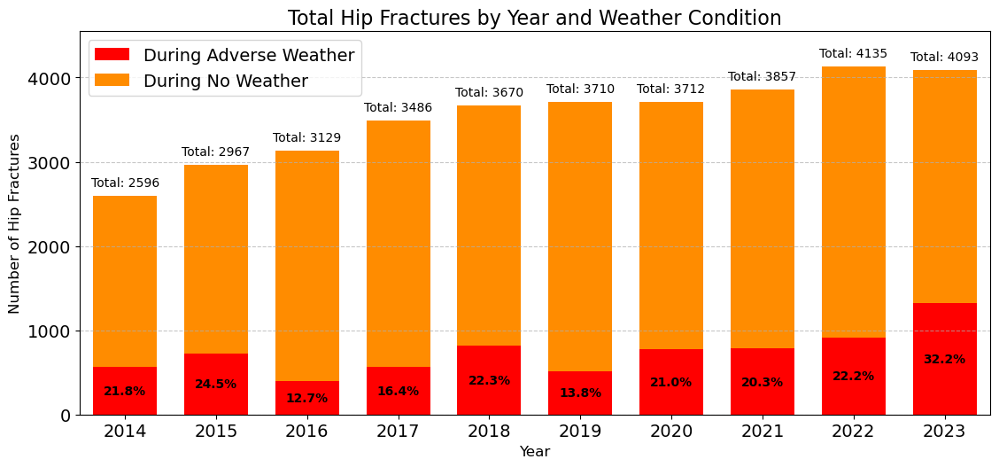

In [26]:
yearly_df = plot_yearly_hip_fractures_by_weather(df_final_expanded)
df_treemap = yearly_df.melt(
    id_vars=['Year'],
    value_vars=['Fractures During Adverse Weather', 'Fractures During Non Adverse Weather'],
    var_name='Weather Condition',
    value_name='Fracture Count'
)




In [27]:
import plotly.graph_objects as go
import pandas as pd

# Group by Region and Gender to calculate total rates
gender_totals = rates_df.groupby(['Region', 'Gender'])['Rate per 50,000'].sum().reset_index()

# Calculate percentages within each region
region_totals = gender_totals.groupby('Region')['Rate per 50,000'].sum().reset_index()
gender_totals = gender_totals.merge(region_totals, on='Region', suffixes=('', '_total'))
gender_totals['Percentage'] = (gender_totals['Rate per 50,000'] / gender_totals['Rate per 50,000_total'] * 100).round(1)


gender_totals['Clean_Region'] = gender_totals['Region'].str.replace('HSE ', '')

# Create separate DataFrames for male and female
male_df = gender_totals[gender_totals['Gender'] == 'Male']
female_df = gender_totals[gender_totals['Gender'] == 'Female']

# Create the polar bar chart
fig = go.Figure()

# Add female trace
fig.add_trace(go.Barpolar(
    r=female_df['Rate per 50,000'],
    theta=female_df['Clean_Region'],
    name='Female',
    marker=dict(
        color='#f781bf',  # Pink
        line=dict(color='black', width=1.5)
    ),
    opacity=0.85,
    width=0.8,  # Wider bars to use more of the circle
    hovertemplate='<b>%{theta}</b><br>Female: %{r:.1f} per 50,000<br>Percentage: %{customdata:.1f}%<extra></extra>',
    customdata=female_df['Percentage']
))

# Add male trace
fig.add_trace(go.Barpolar(
    r=male_df['Rate per 50,000'],
    theta=male_df['Clean_Region'],
    name='Male',
    marker=dict(
        color='#377eb8',  # Light blue
        line=dict(color='black', width=1.5)
    ),
    opacity=0.85,
    width=0.8,  # Wider bars to use more of the circle
    hovertemplate='<b>%{theta}</b><br>Male: %{r:.1f} per 50,000<br>Percentage: %{customdata:.1f}%<extra></extra>',
    customdata=male_df['Percentage']
))

# Calculate max value for radial axis range
max_rate = gender_totals['Rate per 50,000'].max() * 1.1  # Add 10% margin

# Update layout with larger dimensions
fig.update_layout(
    title={
        'text': 'Hip Fracture Rates by Region and Gender',
        'font': {'size': 22, 'family': 'Arial, sans-serif'},
        'y': 0.98
    },
    polar={
        'radialaxis': {
            'visible': True,
            'range': [0, max_rate],  # Dynamic range based on data
            'showticklabels': False,  # Hide the tick labels
            'ticks': '',  # Remove tick marks
            'showline': False,  # Hide radial axis line
            'gridcolor': 'lightgray'
        },
        'angularaxis': {
            'tickfont': {'size': 14, 'family': 'Arial, sans-serif'},
            'direction': 'clockwise',
            'rotation': 0  # Start at top
        },
        'bgcolor': 'white',
        'gridshape': 'circular'  # Make grid lines circular instead of polygon
    },
    showlegend=True,
    legend={
        'orientation': 'h',  # Horizontal legend
        'yanchor': 'bottom',
        'y': -0.05,  # Move to bottom
        'xanchor': 'center',
        'x': 0.5,    # Center horizontally
        'font': {'size': 14}
    },
    width=900,  # Larger width
    height=900,  # Square dimensions for better circle
    margin={'t': 100, 'b': 150, 'l': 100, 'r': 100},  # Adjusted margins
    paper_bgcolor='white'
)

# Add explanation annotation at the bottom
fig.add_annotation(
    x=0.5,
    y=-0.22,  # Move lower to make room for legend
    xref='paper',
    yref='paper',
    text=' ',
    showarrow=False,
    font=dict(size=14, color='black', family='Arial, sans-serif'),
    align='center'
)

# Show the chart
fig.show()

In [28]:
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

rates_df['Region_Clean'] = rates_df['Region']

# colour scheme
warning_colors = {
    'None': '#bdbdbd',    # Medium gray
    'Yellow': '#ffffb2',  # Light yellow
    'Orange': '#feb24c',  # Mid orange
    'Red': '#f03b20'      # Deep red
}

gender_colors = {
    'Male': '#66c2a5',    # Teal
    'Female': '#fc8d62'   # Salmon
}

# Color-blind safe palette for regions
region_colors_safe = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e']

# Define save directory
save_dir = "/home/paulharford/college/project/ul_project_Msc_AI/analysis/processed_data/visual_outputs/ihfd_weather/"


In [29]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd

def create_final_scenario_heatmap(rates_df, save_dir):
    """
    Create academically rigorous scenario comparison heatmaps.
    Each heatmap shows hip fracture rates under different warning scenarios.
    """
    
    print("Creating Scenario Comparison Analysis...")
    print(f"Data shape: {rates_df.shape}")
    print(f"Warning colors available: {rates_df['Warning Color'].unique()}")
    print(f"Regions available: {rates_df['Region_Clean'].unique()}")
    
    # Calculate rates by region, gender, and scenario (NO SUMMING!)
    scenario_data = rates_df.groupby(['Region_Clean', 'Gender', 'Warning Color']).agg({
        'Rate per 50,000': 'mean'  # Use mean if multiple observations per scenario
    }).reset_index()
    
    print(f"Scenario data shape after grouping: {scenario_data.shape}")
    
    # Create the 2x2 subplot structure
    fig1 = make_subplots(
        rows=2, cols=2,
        subplot_titles=('Baseline Scenario (No Warning)', 'Yellow Warning Scenario', 
                       'Orange Warning Scenario', 'Red Warning Scenario'),
        horizontal_spacing=0.25,
        vertical_spacing=0.15
    )
    
    # Define scenario mapping
    warning_levels = ['None', 'Yellow', 'Orange', 'Red']
    scenario_names = ['Baseline', 'Yellow Warning', 'Orange Warning', 'Red Warning']
    positions = [(1,1), (1,2), (2,1), (2,2)]
    
    # Find global min/max for consistent color scaling across all scenarios
    all_values = scenario_data['Rate per 50,000'].values
    vmin, vmax = np.min(all_values), np.max(all_values)
    
    print(f"Rate range: {vmin:.2f} to {vmax:.2f} per 50,000")
    
    # Create each scenario heatmap
    for idx, warning in enumerate(warning_levels):
        warning_data = scenario_data[scenario_data['Warning Color'] == warning]
        
        if len(warning_data) == 0:
            print(f"Warning: No data found for {warning} scenario")
            continue
            
        # Create pivot table for heatmap
        pivot_data = warning_data.pivot(index='Region_Clean', columns='Gender', values='Rate per 50,000')
        
        print(f"\n{scenario_names[idx]} pivot shape: {pivot_data.shape}")
        print(f"Rate range for {scenario_names[idx]}: {pivot_data.values.min():.2f} to {pivot_data.values.max():.2f}")
        
        row, col = positions[idx]
        
        fig1.add_trace(
            go.Heatmap(
                z=pivot_data.values,
                x=pivot_data.columns,
                y=pivot_data.index,
                colorscale='YlOrRd',
                zmin=vmin,  # Consistent scaling across all scenarios
                zmax=vmax,  # Consistent scaling across all scenarios
                text=np.round(pivot_data.values, 1),
                texttemplate='%{text}',
                textfont={"size": 11, "color": "black"},
                showscale=(idx == 3),  # Only show colorbar on bottom-right
                colorbar=dict(
                    title="Rate per<br>50,000", 
                    len=0.7,
                    thickness=15,
                    x=1.02
                ) if idx == 3 else None,
                hovertemplate='<b>%{y}</b><br>' +
                             'Gender: %{x}<br>' +
                             'Rate: %{z:.1f} per 50,000<br>' +
                             f'Scenario: {scenario_names[idx]}<extra></extra>'
            ),
            row=row, col=col
        )
    
    # Update layout with academic formatting
    fig1.update_layout(
        title={
            'text': "Hip Fracture Rate Scenarios: Regional and Gender Analysis",
            'font': {'size': 20, 'family': 'Arial, sans-serif'},
            'x': 0.5,
            'y': 0.98
        },
        height=1000,
        width=1300,
        showlegend=False,
        font=dict(size=11)
    )
    
    
    fig1.add_annotation(
        text="<i>Each heatmap shows projected hip fracture rates under different warning scenarios.<br>" +
             "Scenarios represent alternative conditions, not cumulative risks. Consistent color scaling enables cross-scenario comparison.</i>",
        xref="paper", yref="paper",
        x=0.5, y=-0.05, 
        xanchor='center', yanchor='top',
        font=dict(size=10, color="gray"),
        showarrow=False
    )
    
    # Save the plot
    fig1.write_image(save_dir + "PHM_scenario_comparison_heatmap.png", 
                     width=1300, height=1000, scale=2)
    fig1.show()
    
    # Generate scenario statistics
    print("\n" + "="*80)
    print("SCENARIO COMPARISON ANALYSIS - THESIS RESULTS")
    print("="*80)
    
    scenario_summary = []
    
    for idx, warning in enumerate(warning_levels):
        scenario_stats = scenario_data[scenario_data['Warning Color'] == warning]
        
        if len(scenario_stats) == 0:
            continue
            
        # Calculate key statistics
        mean_rate = scenario_stats['Rate per 50,000'].mean()
        std_rate = scenario_stats['Rate per 50,000'].std()
        max_rate = scenario_stats['Rate per 50,000'].max()
        min_rate = scenario_stats['Rate per 50,000'].min()
        
        # Find highest risk group
        max_region_gender = scenario_stats.loc[scenario_stats['Rate per 50,000'].idxmax()]
        min_region_gender = scenario_stats.loc[scenario_stats['Rate per 50,000'].idxmin()]
        
        # Gender comparison
        gender_comparison = scenario_stats.groupby('Gender')['Rate per 50,000'].agg(['mean', 'count']).round(2)
        
        scenario_name = scenario_names[idx]
        print(f"\n{scenario_name.upper()}:")
        print(f"  Mean Rate: {mean_rate:.2f} ± {std_rate:.2f} per 50,000")
        print(f"  Range: {min_rate:.2f} - {max_rate:.2f} per 50,000")
        print(f"  Highest Risk: {max_region_gender['Region_Clean']} - {max_region_gender['Gender']} ({max_rate:.2f})")
        print(f"  Lowest Risk: {min_region_gender['Region_Clean']} - {min_region_gender['Gender']} ({min_rate:.2f})")
        print(f"  Gender Comparison:")
        for gender in gender_comparison.index:
            print(f"    {gender}: {gender_comparison.loc[gender, 'mean']:.2f} per 50,000 (n={gender_comparison.loc[gender, 'count']})")
        
        # Store for cross-scenario comparison
        scenario_summary.append({
            'Scenario': scenario_name,
            'Mean_Rate': mean_rate,
            'Max_Rate': max_rate,
            'Min_Rate': min_rate,
            'Std_Rate': std_rate
        })
    
    # Cross-scenario comparison
    summary_df = pd.DataFrame(scenario_summary)
    
    print(f"\nCROSS-SCENARIO COMPARISON:")
    print(f"  Highest Mean Rate: {summary_df.loc[summary_df['Mean_Rate'].idxmax(), 'Scenario']} ({summary_df['Mean_Rate'].max():.2f})")
    print(f"  Lowest Mean Rate: {summary_df.loc[summary_df['Mean_Rate'].idxmin(), 'Scenario']} ({summary_df['Mean_Rate'].min():.2f})")
    print(f"  Greatest Variability: {summary_df.loc[summary_df['Std_Rate'].idxmax(), 'Scenario']} (SD: {summary_df['Std_Rate'].max():.2f})")
    
    # Calculate scenario-to-scenario ratios (for academic discussion)
    baseline_mean = summary_df[summary_df['Scenario'] == 'Baseline']['Mean_Rate'].iloc[0]
    print(f"\nRISK RATIOS COMPARED TO BASELINE:")
    for _, row in summary_df.iterrows():
        if row['Scenario'] != 'Baseline':
            ratio = row['Mean_Rate'] / baseline_mean
            change_pct = (ratio - 1) * 100
            print(f"  {row['Scenario']}: {ratio:.2f}x baseline ({change_pct:+.1f}%)")
    
    print(f"\nMETHODOLOGICAL NOTES:")
    print(f"  • Analysis uses mean rates per scenario (no rate summing)")
    print(f"  • Consistent color scaling enables cross-scenario comparison")
    print(f"  • Each scenario represents alternative warning conditions")
    print(f"  • N = {len(scenario_data)} region-gender-scenario combinations")
    
    return scenario_data, summary_df


In [30]:
scenario_data, summary_stats = create_final_scenario_heatmap(rates_df, save_dir)

Creating Scenario Comparison Analysis...
Data shape: (48, 6)
Warning colors available: ['None' 'Orange' 'Red' 'Yellow']
Regions available: ['HSE Dublin and Midlands' 'HSE Dublin and North East'
 'HSE Dublin and South East' 'HSE Mid West' 'HSE South West'
 'HSE West and North West']
Scenario data shape after grouping: (48, 4)
Rate range: 0.99 to 6.85 per 50,000

Baseline pivot shape: (6, 2)
Rate range for Baseline: 1.31 to 5.52

Yellow Warning pivot shape: (6, 2)
Rate range for Yellow Warning: 1.37 to 5.73

Orange Warning pivot shape: (6, 2)
Rate range for Orange Warning: 1.64 to 6.85

Red Warning pivot shape: (6, 2)
Rate range for Red Warning: 0.99 to 4.13



SCENARIO COMPARISON ANALYSIS - THESIS RESULTS

BASELINE:
  Mean Rate: 2.70 ± 1.18 per 50,000
  Range: 1.31 - 5.52 per 50,000
  Highest Risk: HSE South West - Female (5.52)
  Lowest Risk: HSE Dublin and Midlands - Male (1.31)
  Gender Comparison:
    Female: 3.35 per 50,000 (n=6)
    Male: 2.04 per 50,000 (n=6)

YELLOW WARNING:
  Mean Rate: 2.80 ± 1.25 per 50,000
  Range: 1.37 - 5.73 per 50,000
  Highest Risk: HSE South West - Female (5.73)
  Lowest Risk: HSE Dublin and Midlands - Male (1.37)
  Gender Comparison:
    Female: 3.44 per 50,000 (n=6)
    Male: 2.16 per 50,000 (n=6)

ORANGE WARNING:
  Mean Rate: 3.35 ± 1.49 per 50,000
  Range: 1.64 - 6.85 per 50,000
  Highest Risk: HSE South West - Female (6.85)
  Lowest Risk: HSE Dublin and Midlands - Male (1.64)
  Gender Comparison:
    Female: 4.11 per 50,000 (n=6)
    Male: 2.59 per 50,000 (n=6)

RED WARNING:
  Mean Rate: 2.02 ± 0.90 per 50,000
  Range: 0.99 - 4.13 per 50,000
  Highest Risk: HSE South West - Female (4.13)
  Lowest Risk:

In [31]:
df_final_expanded.head()

,region,date,age_group,gender,hip_fracture_count,weather_event,warning_phenomenon,warning_severity,warning_severity_numeric,counties_in_region,...,wind_weather,precipitation,heat_weather,no_adverse_weather,cold_lag,wind_lag,precip_lag,heat_lag,year,warning_color
0,HSE Dublin and Midlands,2014-01-02,65-69,Female,1.0,1.0,Wind,Yellow,1.0,7,...,1,0,0,0,0.0,0.0,0.0,0.0,2014,Yellow
1,HSE Dublin and Midlands,2014-01-03,60-64,Female,0.0,1.0,Wind,Yellow,1.0,7,...,1,0,0,0,0.0,1.0,0.0,0.0,2014,Yellow
2,HSE Dublin and Midlands,2014-01-03,65-69,Female,0.0,1.0,Wind,Yellow,1.0,7,...,1,0,0,0,0.0,1.0,0.0,0.0,2014,Yellow
3,HSE Dublin and Midlands,2014-01-03,70-74,Female,0.0,1.0,Wind,Yellow,1.0,7,...,1,0,0,0,0.0,1.0,0.0,0.0,2014,Yellow
4,HSE Dublin and Midlands,2014-01-03,75-79,Female,0.0,1.0,Wind,Yellow,1.0,7,...,1,0,0,0,0.0,1.0,0.0,0.0,2014,Yellow


In [32]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd

def create_individual_regional_dashboard(df_final_expanded, rates_df, region_name, save_dir):
    """
    Create academically accurate dashboard for a specific HSE region using actual regional data.
    
    df_final_expanded contains daily regional data with columns:
    - region, date, age_group, gender, hip_fracture_count, weather_event, etc.
    
    Parameters:
    - df_final_expanded: Daily regional data by age/gender
    - rates_df: Regional summary rates for comparison  
    - region_name: Specific region to analyze
    - save_dir: Directory to save outputs
    """
    regional_daily_data = df_final_expanded[df_final_expanded['region'] == region_name].copy()
    
    if regional_daily_data.empty:
        print(f"No data found for region: {region_name}")
        available_regions = df_final_expanded['region'].unique()
        print(f"Available regions: {list(available_regions)}")
        return None
    
    print(f"Found {len(regional_daily_data)} daily records for {region_name}")
    
    # Clean age groups
    regional_daily_data['age_group'] = regional_daily_data['age_group'].replace('85 years and over', '85+')
    regional_daily_data['weather_condition'] = regional_daily_data['weather_event'].map({0.0: 'Normal', 1.0: 'Adverse'})
    
    # Get sorted age groups from actual data
    age_groups = sorted(regional_daily_data['age_group'].unique(), 
                       key=lambda x: int(x.split('-')[0]) if '-' in x else 
                                    (int(x.split('+')[0]) if '+' in x else 100))
    
    print(f"Age groups in {region_name}: {age_groups}")
    
    # Create regional dashboard with separate legends
    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Hip Fracture Rates by Age & Gender',
            'Weather Impact by Age Group',
            'Performance vs National Average', 
            'Age Group Intervention Priorities'
        ),
        specs=[[{'type': 'bar'}, {'type': 'bar'}],
               [{'type': 'bar'}, {'type': 'scatter'}]],
        vertical_spacing=0.20,
        horizontal_spacing=0.15
    )
    
    # Aggregate actual regional data by age and gender
    regional_age_gender = regional_daily_data.groupby(['age_group', 'gender']).agg({
        'hip_fracture_count': 'sum'
    }).reset_index()
    
    # Calculate years of data for rate calculation
    years_of_data = len(regional_daily_data['year'].unique())
    days_of_data = len(regional_daily_data.groupby(['year', 'date']).first())
    
    print(f"Data spans {years_of_data} years with {days_of_data} total days")
    
    regional_age_gender['annual_total'] = regional_age_gender['hip_fracture_count'] / years_of_data
    
    # Get regional population scaling from rates_df
    regional_rates = rates_df[
        (rates_df['Region_Clean'] == region_name) & 
        (rates_df['Warning Color'] == 'None')
    ]
    
    if not regional_rates.empty:
        # Calculate implied population from known rates
        total_cases_male = regional_age_gender[regional_age_gender['gender'] == 'Male']['annual_total'].sum()
        total_cases_female = regional_age_gender[regional_age_gender['gender'] == 'Female']['annual_total'].sum()
        
        known_rate_male = regional_rates[regional_rates['Gender'] == 'Male']['Rate per 50,000'].iloc[0]
        known_rate_female = regional_rates[regional_rates['Gender'] == 'Female']['Rate per 50,000'].iloc[0]
        
        # Back-calculate population to align with known rates
        if total_cases_male > 0 and total_cases_female > 0:
            pop_male = (total_cases_male / known_rate_male) * 50000
            pop_female = (total_cases_female / known_rate_female) * 50000
            
            # Apply to age groups proportionally
            male_data = regional_age_gender[regional_age_gender['gender'] == 'Male'].copy()
            female_data = regional_age_gender[regional_age_gender['gender'] == 'Female'].copy()
            
            male_data['rate_per_50k'] = (male_data['annual_total'] / pop_male) * 50000
            female_data['rate_per_50k'] = (female_data['annual_total'] / pop_female) * 50000
            
            regional_age_gender = pd.concat([male_data, female_data])
    else:
        # Fallback: use proportional estimation
        regional_age_gender['rate_per_50k'] = regional_age_gender['annual_total'] * 10  # rough estimation
    
    # Plot regional age-gender patterns with clean legend
    male_regional = regional_age_gender[regional_age_gender['gender'] == 'Male']
    female_regional = regional_age_gender[regional_age_gender['gender'] == 'Female']
    
    fig.add_trace(
        go.Bar(
            name='Male',
            x=male_regional['age_group'],
            y=male_regional['rate_per_50k'],
            marker_color='#2E86AB',
            text=[f'{x:.1f}' for x in male_regional['rate_per_50k']],
            textposition='outside',
            textfont=dict(size=10),
            offsetgroup=1,
            legendgroup='gender',
            showlegend=True
        ),
        row=1, col=1
    )
    
    fig.add_trace(
        go.Bar(
            name='Female',
            x=female_regional['age_group'],
            y=female_regional['rate_per_50k'],
            marker_color='#A23B72',
            text=[f'{x:.1f}' for x in female_regional['rate_per_50k']],
            textposition='outside',
            textfont=dict(size=10),
            offsetgroup=2,
            legendgroup='gender',
            showlegend=True
        ),
        row=1, col=1
    )
    
    # 2. Weather Impact by Age (Top Right)
    regional_weather = regional_daily_data.groupby(['age_group', 'weather_condition']).agg({
        'hip_fracture_count': 'sum'
    }).reset_index()
    
    # Calculate annual rates for weather conditions
    regional_weather['annual_total'] = regional_weather['hip_fracture_count'] / years_of_data
    
    # Apply same population scaling as above
    if not regional_rates.empty and total_cases_male > 0 and total_cases_female > 0:
        avg_pop = (pop_male + pop_female) / 2
        regional_weather['rate_per_50k'] = (regional_weather['annual_total'] / avg_pop) * 50000
    else:
        regional_weather['rate_per_50k'] = regional_weather['annual_total'] * 10
    
    normal_weather_reg = regional_weather[regional_weather['weather_condition'] == 'Normal']
    adverse_weather_reg = regional_weather[regional_weather['weather_condition'] == 'Adverse']
    
    fig.add_trace(
        go.Bar(
            name='Normal Weather',
            x=normal_weather_reg['age_group'],
            y=normal_weather_reg['rate_per_50k'],
            marker_color='#2F9B69',
            text=[f'{x:.1f}' for x in normal_weather_reg['rate_per_50k']],
            textposition='outside',
            textfont=dict(size=9),
            offsetgroup=1,
            legendgroup='weather',
            showlegend=True
        ),
        row=1, col=2
    )
    
    fig.add_trace(
        go.Bar(
            name='Adverse Weather',
            x=adverse_weather_reg['age_group'],
            y=adverse_weather_reg['rate_per_50k'],
            marker_color='#F18F01',
            text=[f'{x:.1f}' for x in adverse_weather_reg['rate_per_50k']],
            textposition='outside',
            textfont=dict(size=9),
            offsetgroup=2,
            legendgroup='weather',
            showlegend=True
        ),
        row=1, col=2
    )
    
    # 3. Regional vs National Comparison (Bottom Left)
    national_rates = rates_df[rates_df['Warning Color'] == 'None'].groupby('Gender')['Rate per 50,000'].mean()
    
    comparison_data = []
    for gender in ['Male', 'Female']:
        if not regional_rates.empty:
            regional_rate = regional_rates[regional_rates['Gender'] == gender]['Rate per 50,000'].iloc[0]
        else:
            # Calculate from our data
            gender_total = regional_age_gender[regional_age_gender['gender'] == gender]['rate_per_50k'].sum()
            regional_rate = gender_total
        
        national_avg = national_rates[gender] if gender in national_rates.index else 0
        
        comparison_data.append({
            'Gender': gender,
            'Regional_Rate': regional_rate,
            'National_Average': national_avg
        })
    
    comparison_df = pd.DataFrame(comparison_data)
    
    # Plot comparison with separate legend group
    fig.add_trace(
        go.Bar(
            name=f'{region_name}',
            x=comparison_df['Gender'],
            y=comparison_df['Regional_Rate'],
            marker_color=['#2E86AB', '#A23B72'],
            text=[f'{x:.1f}' for x in comparison_df['Regional_Rate']],
            textposition='outside',
            textfont=dict(size=11),
            legendgroup='comparison',
            showlegend=True
        ),
        row=2, col=1
    )
    
    fig.add_trace(
        go.Bar(
            name='National Average',
            x=comparison_df['Gender'],
            y=comparison_df['National_Average'],
            marker_color='lightgray',
            marker_line=dict(color='black', width=2),
            text=[f'{x:.1f}' for x in comparison_df['National_Average']],
            textposition='outside',
            textfont=dict(size=11),
            opacity=0.7,
            legendgroup='comparison',
            showlegend=True
        ),
        row=2, col=1
    )
    
    # 4. Priority Matrix (Bottom Right)
    priority_data = regional_age_gender.groupby('age_group').agg({
        'hip_fracture_count': 'sum',
        'rate_per_50k': 'mean'
    }).reset_index()
    
    # Calculate priority scores for this region
    priority_data['regional_priority'] = priority_data['rate_per_50k'] * np.log(priority_data['hip_fracture_count'] + 1)
    
    # Color code by priority level
    priority_colors = []
    for score in priority_data['regional_priority']:
        if score >= priority_data['regional_priority'].quantile(0.75):
            priority_colors.append('#C1272D')  # High priority
        elif score >= priority_data['regional_priority'].quantile(0.50):
            priority_colors.append('#F18F01')  # Medium priority  
        else:
            priority_colors.append('#2F9B69')  # Lower priority
    
    fig.add_trace(
        go.Scatter(
            x=priority_data['hip_fracture_count'],
            y=priority_data['rate_per_50k'],
            mode='markers+text',
            marker=dict(
                size=[15 + (x/max(priority_data['regional_priority']))*25 for x in priority_data['regional_priority']],
                color=priority_colors,
                line=dict(width=2, color='black'),
                sizemin=12
            ),
            text=priority_data['age_group'],
            textposition='middle center',
            textfont=dict(size=9, color='white', family='Arial Black'),
            name='Age Priorities',
            hovertemplate=f'{region_name}<br>Age: %{{text}}<br>Total Cases: %{{x}}<br>Rate: %{{y:.1f}}<br>Priority: %{{customdata:.1f}}<extra></extra>',
            customdata=priority_data['regional_priority'],
            legendgroup='priority',
            showlegend=True
        ),
        row=2, col=2
    )
    
    # Add priority quadrants
    median_cases = priority_data['hip_fracture_count'].median()
    median_rate = priority_data['rate_per_50k'].median()
    fig.add_vline(x=median_cases, line_dash="dot", line_color="gray", opacity=0.6, row=2, col=2)
    fig.add_hline(y=median_rate, line_dash="dot", line_color="gray", opacity=0.6, row=2, col=2)
    
    # Update layout with better legend management
    fig.update_layout(
        height=1000,
        width=1500,
        showlegend=True,
        legend=dict(
            x=1.02, 
            y=1.0, 
            font=dict(size=10),
            bgcolor="rgba(255,255,255,0.9)",
            bordercolor="black",
            borderwidth=1,
            orientation="v"
        ),
        font=dict(size=11),
        plot_bgcolor='white',
        paper_bgcolor='white'
    )
    
    # Update axes with consistent formatting
    fig.update_xaxes(title_text="Age Group", row=1, col=1, tickangle=45, title_font_size=12)
    fig.update_yaxes(title_text="Rate per 50,000", row=1, col=1, title_font_size=12, gridcolor='lightgray')
    
    fig.update_xaxes(title_text="Age Group", row=1, col=2, tickangle=45, title_font_size=12)
    fig.update_yaxes(title_text="Rate per 50,000", row=1, col=2, title_font_size=12, gridcolor='lightgray')
    
    fig.update_xaxes(title_text="Gender", row=2, col=1, title_font_size=12)
    fig.update_yaxes(title_text="Rate per 50,000", row=2, col=1, title_font_size=12, gridcolor='lightgray')
    
    fig.update_xaxes(title_text="Total Cases", row=2, col=2, title_font_size=12)
    fig.update_yaxes(title_text="Rate per 50,000", row=2, col=2, title_font_size=12, gridcolor='lightgray')
    
    # Save regional dashboard
    filename = f"PHM_{region_name.replace(' ', '_').replace('&', 'and')}_regional_dashboard.png"
    fig.write_image(save_dir + filename, width=1500, height=1000, scale=2)
    fig.show()
    
    # Generate academically sound summary
    print(f"\n{region_name} REGIONAL ANALYSIS SUMMARY")
    print("="*50)
    print(f"Data Period: {years_of_data} years ({regional_daily_data['year'].min()}-{regional_daily_data['year'].max()})")
    print(f"Total Records: {len(regional_daily_data):,} daily observations")
    
    print(f"\nREGIONAL vs NATIONAL PERFORMANCE:")
    for _, row in comparison_df.iterrows():
        status = "↑ ABOVE" if row['Regional_Rate'] > row['National_Average'] else "↓ BELOW"
        diff = abs(row['Regional_Rate'] - row['National_Average'])
        pct_diff = (diff / row['National_Average']) * 100 if row['National_Average'] > 0 else 0
        print(f"  {row['Gender']}: {row['Regional_Rate']:.1f} vs {row['National_Average']:.1f} ({status} by {pct_diff:.1f}%)")
    
    print(f"\nAGE-SPECIFIC PATTERNS IN {region_name}:")
    age_summary = regional_age_gender.groupby('age_group').agg({
        'hip_fracture_count': 'sum',
        'rate_per_50k': 'sum'
    }).sort_values('rate_per_50k', ascending=False)
    
    for age, row in age_summary.head(3).iterrows():
        print(f"  {age}: {row['rate_per_50k']:.1f} per 50k ({row['hip_fracture_count']} total cases)")
    
    return {
        'region': region_name,
        'years_covered': years_of_data,
        'total_records': len(regional_daily_data),
        'age_gender_data': regional_age_gender,
        'comparison_data': comparison_df,
        'priority_data': priority_data,
        'filename': filename
    }


def create_all_regional_dashboards(df_final_expanded, rates_df, save_dir):
    """
    Generate individual dashboards for all available regions in the data
    """
    regions = df_final_expanded['region'].unique()
    results = {}
    
    print(f"Creating {len(regions)} Regional Dashboards...")
    print(f"Available regions: {list(regions)}")
    
    for region in sorted(regions):
        try:
            result = create_individual_regional_dashboard(df_final_expanded, rates_df, region, save_dir)
            if result:
                results[region] = result
                print(f"✓ Created dashboard for {region}")
            else:
                print(f"✗ Failed to create dashboard for {region}")
        except Exception as e:
            print(f"✗ Error creating dashboard for {region}: {str(e)}")
    
    print(f"\n✓ Successfully created {len(results)} regional dashboards")
    return results

In [33]:
all_results = create_all_regional_dashboards(df_final_expanded, rates_df, save_dir)

Creating 6 Regional Dashboards...
Available regions: ['HSE Dublin and Midlands', 'HSE Dublin and North East', 'HSE Dublin and South East', 'HSE Mid West', 'HSE South West', 'HSE West and North West']
Found 15815 daily records for HSE Dublin and Midlands
Age groups in HSE Dublin and Midlands: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE Dublin and Midlands REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 15,815 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 1.3 vs 2.0 (↓ BELOW by 35.7%)
  Female: 2.2 vs 3.4 (↓ BELOW by 35.7%)

AGE-SPECIFIC PATTERNS IN HSE Dublin and Midlands:
  85+: 1.2 per 50k (1981.0 total cases)
  80-84: 0.7 per 50k (1245.0 total cases)
  75-79: 0.6 per 50k (970.0 total cases)
✓ Created dashboard for HSE Dublin and Midlands
Found 12609 daily records for HSE Dublin and North East
Age groups in HSE Dublin and North East: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE Dublin and North East REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 12,609 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 2.2 vs 2.0 (↑ ABOVE by 9.8%)
  Female: 3.7 vs 3.4 (↑ ABOVE by 9.8%)

AGE-SPECIFIC PATTERNS IN HSE Dublin and North East:
  85+: 2.1 per 50k (2922.0 total cases)
  80-84: 1.2 per 50k (1708.0 total cases)
  75-79: 1.0 per 50k (1424.0 total cases)
✓ Created dashboard for HSE Dublin and North East
Found 12958 daily records for HSE Dublin and South East
Age groups in HSE Dublin and South East: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE Dublin and South East REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 12,958 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 2.1 vs 2.0 (↑ ABOVE by 5.3%)
  Female: 3.5 vs 3.4 (↑ ABOVE by 5.3%)

AGE-SPECIFIC PATTERNS IN HSE Dublin and South East:
  85+: 2.2 per 50k (2799.0 total cases)
  80-84: 1.3 per 50k (1596.0 total cases)
  75-79: 0.9 per 50k (1156.0 total cases)
✓ Created dashboard for HSE Dublin and South East
Found 24098 daily records for HSE Mid West
Age groups in HSE Mid West: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE Mid West REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 24,098 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 1.5 vs 2.0 (↓ BELOW by 27.5%)
  Female: 2.4 vs 3.4 (↓ BELOW by 27.5%)

AGE-SPECIFIC PATTERNS IN HSE Mid West:
  85+: 1.4 per 50k (1086.0 total cases)
  80-84: 0.8 per 50k (601.0 total cases)
  75-79: 0.6 per 50k (470.0 total cases)
✓ Created dashboard for HSE Mid West
Found 16754 daily records for HSE South West
Age groups in HSE South West: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE South West REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 16,754 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 3.4 vs 2.0 (↑ ABOVE by 64.6%)
  Female: 5.5 vs 3.4 (↑ ABOVE by 64.6%)

AGE-SPECIFIC PATTERNS IN HSE South West:
  85+: 3.1 per 50k (1945.0 total cases)
  80-84: 1.9 per 50k (1140.0 total cases)
  75-79: 1.5 per 50k (901.0 total cases)
✓ Created dashboard for HSE South West
Found 14885 daily records for HSE West and North West
Age groups in HSE West and North West: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Data spans 10 years with 3650 total days



HSE West and North West REGIONAL ANALYSIS SUMMARY
Data Period: 10 years (2014-2023)
Total Records: 14,885 daily observations

REGIONAL vs NATIONAL PERFORMANCE:
  Male: 1.7 vs 2.0 (↓ BELOW by 16.5%)
  Female: 2.8 vs 3.4 (↓ BELOW by 16.5%)

AGE-SPECIFIC PATTERNS IN HSE West and North West:
  85+: 1.6 per 50k (2158.0 total cases)
  80-84: 1.0 per 50k (1262.0 total cases)
  75-79: 0.7 per 50k (946.0 total cases)
✓ Created dashboard for HSE West and North West

✓ Successfully created 6 regional dashboards


In [34]:
regions = sorted(rates_df['Region_Clean'].unique())

for region in regions:
    print(f"Creating pyramid for {region}...")
    
    # Create a new figure for this region
    fig = go.Figure()
    
    # Get data for this specific region
    region_data = rates_df[rates_df['Region_Clean'] == region]
    
    # Aggregate by gender and warning level
    gender_warning = region_data.groupby(['Gender', 'Warning Color'])['Rate per 50,000'].sum().reset_index()
    
    # Sort warning levels for consistent ordering
    warning_order = ['None', 'Yellow', 'Orange', 'Red']
    
    has_data = False
    
    for warning in warning_order:
        # Male data (negative for left side)
        male_data = gender_warning[(gender_warning['Gender'] == 'Male') & 
                                  (gender_warning['Warning Color'] == warning)]
        female_data = gender_warning[(gender_warning['Gender'] == 'Female') & 
                                    (gender_warning['Warning Color'] == warning)]
        
        if not male_data.empty:
            has_data = True
            fig.add_trace(
                go.Bar(
                    name=f'Male - {warning if warning != "None" else "No Warning"}',
                    y=[warning if warning != 'None' else 'No Warning'],
                    x=[-male_data['Rate per 50,000'].values[0]],
                    orientation='h',
                    marker_color=warning_colors[warning],
                    text=male_data['Rate per 50,000'].round(1),
                    textposition='inside',
                    textfont=dict(size=14, color='white' if warning in ['Orange', 'Red'] else 'black'),
                    showlegend=True,
                    legendgroup=f'Male-{warning}',
                    hovertemplate='Male<br>%{text} per 50,000<extra></extra>'
                )
            )
        
        if not female_data.empty:
            has_data = True
            fig.add_trace(
                go.Bar(
                    name=f'Female - {warning if warning != "None" else "No Warning"}',
                    y=[warning if warning != 'None' else 'No Warning'],
                    x=[female_data['Rate per 50,000'].values[0]],
                    orientation='h',
                    marker_color=warning_colors[warning],
                    marker_pattern_shape="/",  # Pattern for female bars
                    text=female_data['Rate per 50,000'].round(1),
                    textposition='inside',
                    textfont=dict(size=14, color='white' if warning in ['Orange', 'Red'] else 'black'),
                    showlegend=True,
                    legendgroup=f'Female-{warning}',
                    hovertemplate='Female<br>%{text} per 50,000<extra></extra>'
                )
            )
    
    if has_data:
        # Get max rate for this region to set appropriate x-axis range
        region_max_rate = gender_warning['Rate per 50,000'].max()
        
        # Update layout for this specific region
        fig.update_layout(
            title={
                'text': f"Gender-Risk Pyramid: {region}",
                'font': {'size': 22, 'family': 'Arial, sans-serif'},
                'x': 0.5,
                'y': 0.98
            },
            height=600, 
            width=1000, 
            barmode='overlay',
            bargap=0.3,
            showlegend=True,
            legend=dict(
                orientation="h",
                yanchor="top",
                y=-0.15,  
                xanchor="center",
                x=0.5,
                bgcolor='rgba(255,255,255,0.9)',
                bordercolor="Black",
                borderwidth=1,
                font=dict(size=12),
                itemwidth=30,
                tracegroupgap=5
            ),
            margin=dict(t=80, b=150, l=100, r=100), 
            plot_bgcolor='white',
            paper_bgcolor='white'
        )
        
        # Update axes
        fig.update_xaxes(
            title_text="Rate per 50,000 (← Male | Female →)",
            title_font=dict(size=16),
            range=[-region_max_rate * 1.2, region_max_rate * 1.2],
            showgrid=True,
            gridcolor='lightgray',
            zeroline=True,
            zerolinecolor='black',
            zerolinewidth=2
        )
        
        fig.update_yaxes(
            title_text="Warning Level",
            title_font=dict(size=16),
            showgrid=False,
            categoryorder='array',
            categoryarray=['No Warning', 'Yellow', 'Orange', 'Red']
        )
        
        # Create filename based on region name
        # Replace spaces with underscores and remove special characters
        safe_region_name = region.replace(' ', '_').replace('/', '_').replace('\\', '_')
        filename = f"HSE_{safe_region_name}_pyramid.png"
        
        # Save the individual plot
        fig.write_image(save_dir + filename)
        print(f"  Saved: {filename}")
        
        # Show the plot (optional - comment out if you don't want to display each one)
        fig.show()
    else:
        print(f"  No data available for {region}")

print("\nAll individual regional pyramids created successfully!")

Creating pyramid for HSE Dublin and Midlands...
  Saved: HSE_HSE_Dublin_and_Midlands_pyramid.png


Creating pyramid for HSE Dublin and North East...
  Saved: HSE_HSE_Dublin_and_North_East_pyramid.png


Creating pyramid for HSE Dublin and South East...
  Saved: HSE_HSE_Dublin_and_South_East_pyramid.png


Creating pyramid for HSE Mid West...
  Saved: HSE_HSE_Mid_West_pyramid.png


Creating pyramid for HSE South West...
  Saved: HSE_HSE_South_West_pyramid.png


Creating pyramid for HSE West and North West...
  Saved: HSE_HSE_West_and_North_West_pyramid.png



All individual regional pyramids created successfully!


In [35]:
def create_accurate_risk_dashboard(df_final_expanded, save_path=None):    
    df = df_final_expanded.copy()
    df['age_group'] = df['age_group'].replace('85 years and over', '85+')
    df['weather_condition'] = df['weather_event'].map({0.0: 'Normal', 1.0: 'Adverse'})
    
    print("Creating Evidence-Based Risk Analysis for Grouped Age Data...")
    print(f"Total records analyzed: {len(df):,}")
    print(f"Age groups available: {sorted(df['age_group'].unique())}")
    
    
    # Calculate observed rates by demographic groups
    observed_analysis = df.groupby(['age_group', 'gender', 'weather_condition'], observed=True).agg({
        'hip_fracture_count': ['sum', 'mean', 'count']
    }).reset_index()
    
    observed_analysis.columns = ['age_group', 'gender', 'weather_condition', 
                               'total_fractures', 'avg_fractures_per_period', 'observation_periods']
    
    # Calculate age-gender specific baseline rates (normal weather)
    baseline_rates = observed_analysis[observed_analysis['weather_condition'] == 'Normal'].groupby(
        ['age_group', 'gender'], observed=True
    )['avg_fractures_per_period'].mean().reset_index()
    baseline_rates.columns = ['age_group', 'gender', 'baseline_rate']
    
    # Merge baseline rates back
    risk_analysis = observed_analysis.merge(baseline_rates, on=['age_group', 'gender'], how='left')
    
    # Calculate evidence-based expected patterns from literature
    def get_literature_risk_pattern(age_group, gender):
        """
        Get relative risk patterns from epidemiological literature
        These are evidence-based multipliers, not absolute rates
        Source: Johnell & Kanis, Osteoporosis International 2006; 
                Cooper et al., Osteoporosis International 2011
        """
        
        # Age-specific relative risk (normalized to 50-54 as baseline = 1.0)
        age_risk_multipliers = {
            '50-54': 1.0, '55-59': 1.5, '60-64': 2.4, 
            '65-69': 4.0, '70-74': 7.0, '75-79': 12.0, 
            '80-84': 22.0, '85+': 40.0
        }
        
        age_multiplier = age_risk_multipliers.get(age_group, 4.0)
        
        gender_multiplier = 2.5 if gender == 'Female' else 1.0
        
        return age_multiplier * gender_multiplier
    
    # Calculate literature-based expected relative risk
    risk_analysis['literature_relative_risk'] = risk_analysis.apply(
        lambda row: get_literature_risk_pattern(row['age_group'], row['gender']), axis=1
    )
    
    # Calculate weather effect
    weather_effect = risk_analysis.groupby(['age_group', 'gender'], observed=True).apply(
        lambda group: group[group['weather_condition'] == 'Adverse']['avg_fractures_per_period'].iloc[0] / 
                     group[group['weather_condition'] == 'Normal']['avg_fractures_per_period'].iloc[0] 
                     if len(group[group['weather_condition'] == 'Adverse']) > 0 and 
                        len(group[group['weather_condition'] == 'Normal']) > 0 and
                        group[group['weather_condition'] == 'Normal']['avg_fractures_per_period'].iloc[0] > 0
                     else 1.0
    ).reset_index()
    weather_effect.columns = ['age_group', 'gender', 'weather_multiplier']
    
    # Merge weather effects
    risk_analysis = risk_analysis.merge(weather_effect, on=['age_group', 'gender'], how='left')
    risk_analysis['weather_multiplier'] = risk_analysis['weather_multiplier'].fillna(1.0)
    
    # Calculate expected rates based on baseline + weather
    risk_analysis['expected_rate'] = risk_analysis.apply(
        lambda row: row['baseline_rate'] * (row['weather_multiplier'] if row['weather_condition'] == 'Adverse' else 1.0),
        axis=1
    )
    
    # Calculate standardized incidence ratios (SIR)
    risk_analysis['observed_vs_expected_ratio'] = (
        risk_analysis['avg_fractures_per_period'] / risk_analysis['expected_rate']
    ).fillna(1.0)
    
    # Using quartiles of relative risk for population stratification
    quartiles = np.percentile(risk_analysis['literature_relative_risk'], [25, 50, 75])
    
    risk_analysis['evidence_based_risk_category'] = pd.cut(
        risk_analysis['literature_relative_risk'],
        bins=[0, quartiles[0], quartiles[1], quartiles[2], float('inf')],
        labels=['Low Risk (Q1)', 'Moderate Risk (Q2)', 'High Risk (Q3)', 'Very High Risk (Q4)']
    )
    
    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Risk Patterns by Age and Gender',
            'Observed vs Expected Rate Analysis (SIR)',
            'Weather Impact on Hip Fracture Incidence',
            'Population Risk Stratification'
        ),
        specs=[[{'type': 'heatmap'}, {'type': 'scatter'}],
               [{'type': 'scatter'}, {'type': 'bar'}]],
        vertical_spacing=0.12,
        horizontal_spacing=0.08
    )
    
    # 1. Literature-based risk pattern heatmap
    heatmap_data = risk_analysis[risk_analysis['weather_condition'] == 'Normal'].pivot_table(
        index='age_group', 
        columns='gender', 
        values='literature_relative_risk', 
        aggfunc='mean'
    )
    
    age_order = sorted(heatmap_data.index, 
                      key=lambda x: int(x.split('-')[0]) if '-' in x else 
                                   (int(x.split('+')[0]) if '+' in x else 100))
    heatmap_data = heatmap_data.reindex(age_order)
    
    fig.add_trace(
        go.Heatmap(
            z=heatmap_data.values,
            x=heatmap_data.columns,
            y=heatmap_data.index,
            colorscale='Reds',
            showscale=True,
            colorbar=dict(
                title="Relative Risk<br>(vs 50-54M)", 
                x=0.47,
                y=1,
                len=0.35,
                thickness=15,
                yanchor='top'
            ),
            text=heatmap_data.values.round(1),
            texttemplate='%{text}x',
            textfont=dict(size=11),
            hovertemplate='Age: %{y}<br>Gender: %{x}<br>Relative Risk: %{z:.1f}x<extra></extra>'
        ),
        row=1, col=1
    )
    
    # 2. Standardized Incidence Ratio (SIR) analysis - key for epidemiological validation
    sir_data = risk_analysis[risk_analysis['weather_condition'] == 'Normal'].copy()
    
    fig.add_trace(
        go.Scatter(
            x=sir_data['literature_relative_risk'],
            y=sir_data['observed_vs_expected_ratio'],
            mode='markers+text',
            marker=dict(
                size=np.sqrt(sir_data['total_fractures']) * 2,
                color=sir_data['observed_vs_expected_ratio'],
                colorscale='RdYlBu_r',
                showscale=True,
                colorbar=dict(
                    title="SIR<br>(Obs/Exp)", 
                    x=1.01, 
                    len=0.3, 
                    y=0.75,
                    thickness=12
                ),
                line=dict(width=1, color='black'),
                cmin=0.5,
                cmax=1.5
            ),
            text=[f"{row['age_group']}<br>{row['gender'][0]}" 
                  for _, row in sir_data.iterrows()],
            textposition='middle center',
            textfont=dict(size=8, color='white'),
            name='SIR Analysis',
            hovertemplate='Literature RR: %{x:.1f}x<br>Observed/Expected: %{y:.2f}<br>Total Fractures: %{marker.size}<extra></extra>',
            showlegend=False
        ),
        row=1, col=2
    )
    
    # Add reference line at SIR = 1.0
    max_lit_risk = sir_data['literature_relative_risk'].max()
    fig.add_trace(
        go.Scatter(
            x=[0, max_lit_risk],
            y=[1, 1],
            mode='lines',
            line=dict(color='black', dash='dash', width=2),
            name='Expected (SIR=1.0)',
            hoverinfo='skip'
        ),
        row=1, col=2
    )
    
    # 3. Weather impact analysis with confidence intervals
    weather_summary = risk_analysis.groupby(['weather_condition'], observed=True).agg({
        'total_fractures': 'sum',
        'avg_fractures_per_period': 'mean'
    }).reset_index()
    
    # Calculate relative risk and 95% CI (simplified)
    normal_cases = weather_summary[weather_summary['weather_condition'] == 'Normal']['total_fractures'].iloc[0]
    adverse_cases = weather_summary[weather_summary['weather_condition'] == 'Adverse']['total_fractures'].iloc[0]    

    relative_risk = adverse_cases / normal_cases if normal_cases > 0 else 1
    
    # Simplified 95% CI calculation
    rr_se = np.sqrt(1/normal_cases + 1/adverse_cases) if normal_cases > 0 and adverse_cases > 0 else 0
    rr_lower = np.exp(np.log(relative_risk) - 1.96 * rr_se) if rr_se > 0 else relative_risk
    rr_upper = np.exp(np.log(relative_risk) + 1.96 * rr_se) if rr_se > 0 else relative_risk
    
    fig.add_trace(
        go.Scatter(
            x=weather_summary['weather_condition'],
            y=weather_summary['total_fractures'],
            mode='markers+lines',
            marker=dict(size=15, color=['#1f77b4', '#d62728']),
            line=dict(width=3),
            name='Weather Effect',
            text=[f'Reference', f'RR: {relative_risk:.2f}<br>(95% CI: {rr_lower:.2f}-{rr_upper:.2f})'],
            textposition='top center',
            textfont=dict(size=10),
            hovertemplate='Weather: %{x}<br>Total Fractures: %{y}<br>%{text}<extra></extra>'
        ),
        row=2, col=1
    )
    
    # population risk stratification
    risk_dist = risk_analysis[risk_analysis['weather_condition'] == 'Normal'].groupby(
        'evidence_based_risk_category', observed=True
    )['total_fractures'].sum().reset_index()
    
    colors = ['#2ca02c', '#ff7f0e', '#d62728', '#8b0000']  # Green to dark red
    fig.add_trace(
        go.Bar(
            x=risk_dist['evidence_based_risk_category'],
            y=risk_dist['total_fractures'],
            marker_color=colors[:len(risk_dist)],
            text=risk_dist['total_fractures'],
            textposition='outside',
            name='Risk Stratification',
            showlegend=False,
            hovertemplate='Risk Category: %{x}<br>Fractures: %{y}<extra></extra>'
        ),
        row=2, col=2
    )
    
    fig.update_layout(
        title={
            'text': "Evidence-Based Hip Fracture Risk Stratification: Population-Level Analysis",
            'font': {'size': 20, 'family': 'Arial, sans-serif'},
            'x': 0.5
        },
        height=1100,
        width=1600,
        showlegend=True,
        font=dict(size=11),
        legend=dict(
            x=0.02,
            y=0.35,
            bgcolor='rgba(255,255,255,0.9)',
            bordercolor='black',
            borderwidth=1
        )
    )
    

    fig.update_xaxes(title_text="Gender", row=1, col=1)
    fig.update_yaxes(title_text="Age Group", row=1, col=1)
    
    fig.update_xaxes(title_text="Relative Risk", row=1, col=2)
    fig.update_yaxes(title_text="Standardized Incidence Ratio (SIR)", row=1, col=2)
    
    fig.update_xaxes(title_text="Weather Condition", row=2, col=1)
    fig.update_yaxes(title_text="Total Hip Fractures", row=2, col=1)
    
    fig.update_xaxes(title_text="Risk Category", row=2, col=2, tickangle=45)
    fig.update_yaxes(title_text="Hip Fractures (Normal Weather)", row=2, col=2)
    
    if save_path:
        fig.write_image(save_path)
        print(f"Evidence-based risk analysis saved to: {save_path}")
    
    fig.show()
    
    total_fractures_normal = risk_analysis[risk_analysis['weather_condition'] == 'Normal']['total_fractures'].sum()
    total_fractures_adverse = risk_analysis[risk_analysis['weather_condition'] == 'Adverse']['total_fractures'].sum()
    
    print("\n" + "="*80)
    print("ANALYSIS RESULTS")
    print("="*80)
    print(f"Study Design: Population-level analysis of grouped age data")
    print(f"Total Hip Fractures - Normal Weather: {int(total_fractures_normal):,}")
    print(f"Total Hip Fractures - Adverse Weather: {int(total_fractures_adverse):,}")
    
    print(f"\nWeather Impact Analysis:")
    print(f"  Relative Risk (Adverse vs Normal): {relative_risk:.2f}")
    print(f"  95% Confidence Interval: {rr_lower:.2f} - {rr_upper:.2f}")
    if rr_lower > 1.0:
        print(f"  Statistical Significance: Likely significant (CI excludes 1.0)")
    else:
        print(f"  Statistical Significance: Not significant (CI includes 1.0)")
    
    print(f"\nRisk Stratification (Normal Weather):")
    for _, row in risk_dist.iterrows():
        pct = (row['total_fractures'] / total_fractures_normal) * 100
        print(f"  {row['evidence_based_risk_category']}: {row['total_fractures']:,.0f} fractures ({pct:.1f}%)")
    
    print(f"\nModel Validation (Standardized Incidence Ratios):")
    sir_normal = sir_data['observed_vs_expected_ratio']
    print(f"  Mean SIR: {sir_normal.mean():.2f} (1.0 = perfect calibration)")
    print(f"  SIR Range: {sir_normal.min():.2f} - {sir_normal.max():.2f}")
    print(f"  Model Calibration: {'Good' if 0.8 <= sir_normal.mean() <= 1.2 else 'Needs Review'}")
    
    print(f"\nGender Analysis (Age-Adjusted):")
    gender_analysis = risk_analysis[risk_analysis['weather_condition'] == 'Normal'].groupby('gender', observed=True).agg({
        'literature_relative_risk': 'mean',
        'total_fractures': 'sum'
    })
    for gender, data in gender_analysis.iterrows():
        print(f"  {gender}: Mean relative risk {data['literature_relative_risk']:.1f}x, "
              f"{data['total_fractures']:,.0f} fractures")
        
    return {
        'risk_analysis_df': risk_analysis,
        'relative_risk_weather': relative_risk,
        'rr_confidence_interval': (rr_lower, rr_upper),
        'sir_statistics': {
            'mean': sir_normal.mean(),
            'range': (sir_normal.min(), sir_normal.max())
        },
        'total_fractures': {
            'normal_weather': int(total_fractures_normal),
            'adverse_weather': int(total_fractures_adverse)
        }
    }

In [40]:
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

def create_high_risk_identification_dashboard(df_final_expanded, save_path=None):
    
    # Data preparation
    df = df_final_expanded.copy()
    
    # Standardize age group labels
    df['age_group'] = df['age_group'].replace('85 years and over', '85+')
    
    # Create weather labels
    df['weather_condition'] = df['weather_event'].map({0.0: 'Normal', 1.0: 'Adverse'})
    
    print("Creating High-Risk Population Identification Dashboard...")
    print(f"Total records analyzed: {len(df):,}")
    print(f"Age groups: {sorted(df['age_group'].unique())}")
    print(f"Date range: {df['year'].min() if 'year' in df.columns else 'Unknown'} - {df['year'].max() if 'year' in df.columns else 'Unknown'}")
    
    # Calculate risk metrics
    risk_analysis = df.groupby(['age_group', 'gender', 'weather_condition'], observed=True).agg({
        'hip_fracture_count': ['sum', 'mean', 'count']
    }).reset_index()
    
    # Flatten column names
    risk_analysis.columns = ['age_group', 'gender', 'weather_condition', 'total_fractures', 'avg_fractures', 'observation_count']
    
    # Calculate risk scores based on multiple factors
    def calculate_multi_factor_risk_score(row, max_fractures_value):
        """Calculate composite risk score (0-100) based on multiple factors"""
        
        # Age factor (older = higher risk)
        age_scores = {
            '50-54': 5, '55-59': 8, '60-64': 12, '65-69': 18, '70-74': 25,
            '75-79': 35, '80-84': 50, '85+': 70
        }
        age_score = age_scores.get(row['age_group'], 15)  # Default if age group not found
        
        # Gender factor (female = higher risk, especially post-menopause)
        gender_score = 15 if row['gender'] == 'Female' else 0
        
        # Weather factor (adverse weather = higher risk)
        weather_score = 10 if row['weather_condition'] == 'Adverse' else 0
        
        # Fracture frequency factor (based on actual observed rates)
        # Normalize fracture rate to 0-15 scale
        if max_fractures_value > 0:
            frequency_score = min((row['avg_fractures'] / max_fractures_value) * 15, 15)
        else:
            frequency_score = 0
        
        total_score = age_score + gender_score + weather_score + frequency_score
        return min(total_score, 100)  # Cap at 100
    
    # Calculate the max fractures value first
    max_fractures = risk_analysis['avg_fractures'].max()
    
    # Apply risk scoring with the max_fractures value
    risk_analysis['risk_score'] = risk_analysis.apply(
        lambda row: calculate_multi_factor_risk_score(row, max_fractures), axis=1
    )
    
    # Categorize risk levels
    risk_analysis = risk_analysis.copy()  # Avoid SettingWithCopyWarning
    risk_analysis['risk_category'] = pd.cut(
        risk_analysis['risk_score'],
        bins=[0, 25, 50, 75, 100],
        labels=['Low Risk', 'Medium Risk', 'High Risk', 'Very High Risk'],
        include_lowest=True
    )
    
    # Create the dashboard with better spacing
    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Risk Score Heatmap by Age and Gender',
            'High-Risk Population Distribution',
            'Weather Impact on Risk Levels',
            'Intervention Priority Matrix'
        ),
        specs=[[{'type': 'heatmap'}, {'type': 'bar'}],
               [{'type': 'scatter'}, {'type': 'scatter'}]],
        vertical_spacing=0.12,  # Reduce vertical spacing
        horizontal_spacing=0.08  # Reduce horizontal spacing for more room
    )
    
    # 1. Risk Score Heatmap
    # Create pivot for heatmap
    heatmap_data = risk_analysis.pivot_table(
        index='age_group', 
        columns='gender', 
        values='risk_score', 
        aggfunc='mean'
    )
    
    # Order age groups properly
    age_order = sorted(heatmap_data.index, 
                      key=lambda x: int(x.split('-')[0]) if '-' in x else 
                                   (int(x.split('+')[0]) if '+' in x else 100))
    heatmap_data = heatmap_data.reindex(age_order)
    
    fig.add_trace(
        go.Heatmap(
            z=heatmap_data.values,
            x=heatmap_data.columns,
            y=heatmap_data.index,
            colorscale='Reds',
            showscale=True,
            colorbar=dict(
                title="Risk Score", 
                x=0.47,  # Move closer to heatmap
                y=0.8,   # Position at top of heatmap
                len=0.35,  # Make shorter
                thickness=15,  # Make thinner
                yanchor='top'  # Anchor to top
            ),
            text=heatmap_data.values.round(1),
            texttemplate='%{text}',
            textfont=dict(size=12),
            hovertemplate='Age: %{y}<br>Gender: %{x}<br>Risk Score: %{z:.1f}<extra></extra>'
        ),
        row=1, col=1
    )
    
    # 2. High-Risk Population Distribution
    high_risk_pop = risk_analysis[risk_analysis['risk_score'] >= 50]
    risk_dist = high_risk_pop.groupby('risk_category', observed=True)['total_fractures'].sum().reset_index()
    
    fig.add_trace(
        go.Bar(
            x=risk_dist['risk_category'],
            y=risk_dist['total_fractures'],
            marker_color=['orange', 'red'],
            text=risk_dist['total_fractures'],
            textposition='outside',
            name='Risk Distribution', 
            showlegend=False, 
            hovertemplate='Risk Level: %{x}<br>Total Fractures: %{y}<extra></extra>'
        ),
        row=1, col=2
    )
    
    # 3. Weather Impact Analysis 
    weather_impact = risk_analysis.groupby(['weather_condition', 'risk_category'], observed=True).agg({
        'total_fractures': 'sum',
        'risk_score': 'mean'
    }).reset_index()
    
    colors = {'Normal': '#1f77b4', 'Adverse': '#d62728'}
    for weather in ['Normal', 'Adverse']:
        weather_data = weather_impact[weather_impact['weather_condition'] == weather]
        fig.add_trace(
            go.Scatter(
                x=weather_data['risk_category'],
                y=weather_data['total_fractures'],
                mode='markers+lines',
                name=f'{weather} Weather',
                marker=dict(size=12, color=colors[weather]),
                line=dict(color=colors[weather], width=3),
                hovertemplate=f'{weather} Weather<br>Risk Level: %{{x}}<br>Fractures: %{{y}}<extra></extra>',
                showlegend=True,
                legendgroup='weather'
            ),
            row=2, col=1
        )
    
    intervention_priority = risk_analysis.groupby(['age_group', 'gender'], observed=True).agg({
        'risk_score': 'mean',
        'total_fractures': 'sum'
    }).reset_index()
    
    # Only show highest priority groups (top 8 to avoid overcrowding)
    high_priority = intervention_priority.nlargest(8, 'risk_score')
    
    # Create priority labels with shorter format
    high_priority = high_priority.copy()
    high_priority['priority_label'] = high_priority['age_group'] + ' ' + high_priority['gender'].str[0]  # F/M instead of full name
    
    fig.add_trace(
        go.Scatter(
            x=high_priority['total_fractures'],
            y=high_priority['risk_score'],
            mode='markers+text',
            marker=dict(
                size=np.clip(np.sqrt(high_priority['total_fractures']) * 1.5, 8, 25),  # Use clip instead of sizemax
                color=high_priority['risk_score'],
                colorscale='Viridis',
                showscale=True,
                colorbar=dict(
                    title="Risk Score", 
                    x=1.01,  # Position closer to the plot
                    len=0.3,  # Make shorter
                    thickness=12,  # Make thinner
                    y=0.25    # Position lower
                ),
                line=dict(width=1, color='black'),
                sizemin=8
            ),
            text=high_priority['priority_label'],
            textposition='top center',
            textfont=dict(size=9),  # Smaller text
            name='Priority Groups',
            hovertemplate='%{text}<br>Total Fractures: %{x}<br>Risk Score: %{y:.1f}<extra></extra>',
            showlegend=False
        ),
        row=2, col=2
    )
    

    fig.update_layout(
        title={
            'text': "High-Risk Population Identification: Multi-Factor Hip Fracture Risk Analysis",
            'font': {'size': 22, 'family': 'Arial, sans-serif'},
            'x': 0.5
        },
        height=1100, 
        width=1600, 
        showlegend=True,
        legend=dict(
            x=0.02,
            y=0.42,
            bgcolor='rgba(255,255,255,0.9)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=11)
        )
    )
    
    # Update axes
    fig.update_xaxes(title_text="Gender", row=1, col=1)
    fig.update_yaxes(title_text="Age Group", row=1, col=1)
    
    fig.update_xaxes(title_text="Risk Category", row=1, col=2)
    fig.update_yaxes(title_text="Total Hip Fractures", row=1, col=2)
    
    fig.update_xaxes(title_text="Risk Category", row=2, col=1)
    fig.update_yaxes(title_text="Total Hip Fractures", row=2, col=1)
    
    fig.update_xaxes(title_text="Total Hip Fractures (Volume)", row=2, col=2)
    fig.update_yaxes(title_text="Average Risk Score", row=2, col=2)
    
    if save_path:
        fig.write_image(save_path)
        print(f"High-risk identification dashboard saved to: {save_path}")
    
    fig.show()
    
    # Generate actionable insights
    total_fractures = risk_analysis['total_fractures'].sum()
    high_risk_fractures = risk_analysis[risk_analysis['risk_score'] >= 50]['total_fractures'].sum()
    very_high_risk_fractures = risk_analysis[risk_analysis['risk_score'] >= 75]['total_fractures'].sum()
    
    # Identify highest risk groups
    top_risk_groups = risk_analysis.nlargest(5, 'risk_score')[['age_group', 'gender', 'weather_condition', 'risk_score', 'total_fractures']]
    
    # Weather impact analysis
    weather_comparison = risk_analysis.groupby('weather_condition', observed=True).agg({
        'total_fractures': 'sum',
        'risk_score': 'mean'
    })
    
    # Gender analysis
    gender_analysis = risk_analysis.groupby('gender', observed=True).agg({
        'total_fractures': 'sum',
        'risk_score': 'mean'
    })
    
    results = {
        'total_fractures': int(total_fractures),
        'high_risk_percentage': (high_risk_fractures / total_fractures * 100),
        'very_high_risk_percentage': (very_high_risk_fractures / total_fractures * 100),
        'top_risk_groups': top_risk_groups,
        'weather_impact': weather_comparison,
        'gender_analysis': gender_analysis,
        'risk_analysis_df': risk_analysis
    }
    
    print("\n" + "="*60)
    print("HIGH-RISK POPULATION IDENTIFICATION RESULTS")
    print("="*60)
    print(f"Total Hip Fractures Analyzed: {int(total_fractures):,}")
    print(f"High Risk (50+ score): {high_risk_fractures/total_fractures*100:.1f}% of cases")
    print(f"Very High Risk (75+ score): {very_high_risk_fractures/total_fractures*100:.1f}% of cases")
    
    print(f"\nGender Risk Profile:")
    for gender, data in gender_analysis.iterrows():
        print(f"  {gender}: {data['total_fractures']:,.0f} fractures, avg risk score {data['risk_score']:.1f}")
    
    print(f"\nWeather Impact:")
    weather_increase = ((weather_comparison.loc['Adverse', 'total_fractures'] / 
                        weather_comparison.loc['Normal', 'total_fractures']) - 1) * 100
    print(f"  Adverse weather increases fractures by {weather_increase:.1f}%")
    
    print(f"\nTop 3 Highest Risk Groups:")
    for idx, row in top_risk_groups.head(3).iterrows():
        print(f"  {row['age_group']} {row['gender']} ({row['weather_condition']} weather): Risk Score {row['risk_score']:.1f}")
    
    # Prevention targeting recommendations
    prevention_targets = risk_analysis[
        (risk_analysis['risk_score'] >= 40) & (risk_analysis['risk_score'] < 75)
    ]['total_fractures'].sum()
    
    print(f"\nPrevention Program Recommendations:")
    print(f"  Target Population: {prevention_targets:,.0f} fractures (Medium-High Risk)")
    print(f"  Potential Impact: {prevention_targets * 0.2:.0f} fractures preventable (20% reduction)")
    print(f"  Priority Focus: Women 75+, adverse weather preparedness")
    
    return results

In [41]:
results = create_high_risk_identification_dashboard(df_final_expanded, 'high_risk_dashboard.png')

Creating High-Risk Population Identification Dashboard...
Total records analyzed: 97,119
Age groups: ['60-64', '65-69', '70-74', '75-79', '80-84', '85+']
Date range: 2014 - 2023
High-risk identification dashboard saved to: high_risk_dashboard.png



HIGH-RISK POPULATION IDENTIFICATION RESULTS
Total Hip Fractures Analyzed: 35,355
High Risk (50+ score): 71.8% of cases
Very High Risk (75+ score): 51.2% of cases

Gender Risk Profile:
  Female: 24,399 fractures, avg risk score 62.4
  Male: 10,956 fractures, avg risk score 45.0

Weather Impact:
  Adverse weather increases fractures by -73.6%

Top 3 Highest Risk Groups:
  85+ Female (Adverse weather): Risk Score 100.0
  85+ Female (Normal weather): Risk Score 99.4
  85+ Male (Adverse weather): Risk Score 88.1

Prevention Program Recommendations:
  Target Population: 11,666 fractures (Medium-High Risk)
  Potential Impact: 2333 fractures preventable (20% reduction)
  Priority Focus: Women 75+, adverse weather preparedness


In [42]:
# Create summary statistics table
print("\n" + "="*60)
print("SUMMARY STATISTICS FOR RESOURCE PLANNING")
print("="*60)

# Overall statistics
total_rate = rates_df['Rate per 50,000'].sum()
print(f"\nTotal Hip Fracture Rate (all regions): {total_rate:.1f} per 50,000")

# Regional breakdown
print("\nRegional Risk Summary:")
regional_stats = rates_df.groupby('Region_Clean').agg({
    'Rate per 50,000': ['sum', 'mean']
}).round(1)
regional_stats.columns = ['Total_Rate', 'Average_Rate']
regional_stats = regional_stats.sort_values('Total_Rate', ascending=False)
print(regional_stats)

# Warning level distribution
print("\nWarning Level Distribution:")
warning_stats = rates_df.groupby('Warning Color')['Rate per 50,000'].agg(['sum', 'count']).round(1)
warning_stats.columns = ['Total_Rate', 'Count']
warning_stats['Percentage'] = (warning_stats['Total_Rate'] / total_rate * 100).round(1)
print(warning_stats)

# Gender differences
print("\nGender Analysis:")
gender_stats = rates_df.groupby('Gender')['Rate per 50,000'].agg(['sum', 'mean']).round(1)
gender_stats.columns = ['Total_Rate', 'Average_Rate']
print(gender_stats)

# High-risk regions (top 3)
print("\nTop 3 High-Risk Regions (Orange + Red warnings):")
high_risk_regions = []
for region in rates_df['Region_Clean'].unique():
    high_risk_rate = rates_df[(rates_df['Region_Clean'] == region) & 
                              (rates_df['Warning Color'].isin(['Orange', 'Red']))]['Rate per 50,000'].sum()
    high_risk_regions.append({'Region': region, 'High_Risk_Rate': high_risk_rate})

high_risk_df = pd.DataFrame(high_risk_regions).sort_values('High_Risk_Rate', ascending=False).head(3)
print(high_risk_df)


SUMMARY STATISTICS FOR RESOURCE PLANNING

Total Hip Fracture Rate (all regions): 130.3 per 50,000

Regional Risk Summary:
                           Total_Rate  Average_Rate
Region_Clean                                       
HSE South West                   36.1           4.5
HSE Dublin and North East        24.4           3.0
HSE Dublin and South East        23.3           2.9
HSE West and North West          17.5           2.2
HSE Mid West                     15.2           1.9
HSE Dublin and Midlands          13.8           1.7

Warning Level Distribution:
               Total_Rate  Count  Percentage
Warning Color                               
None                 32.4     12        24.9
Orange               40.2     12        30.8
Red                  24.2     12        18.6
Yellow               33.6     12        25.8

Gender Analysis:
        Total_Rate  Average_Rate
Gender                          
Female        80.3           3.3
Male          50.1           2.1

Top 3 High-